In [1]:
import warnings

with warnings.catch_warnings():
    warnings.simplefilter(action="ignore", category=FutureWarning)

    import os, math
    from pathlib import Path
    import scanpy as sc
    import numpy as np
    import seaborn as sns
    import pandas as pd
    import matplotlib as mpl
    import matplotlib.pyplot as plt
    from tqdm import tqdm
    from scipy import stats
    from scipy.stats import pearsonr, spearmanr
    from scipy.sparse import issparse

    from scipy.stats import wilcoxon, rankdata
    from statsmodels.stats.multitest import multipletests
    from itertools import combinations

    pd.set_option("display.max_rows", 500)
    pd.set_option("display.max_columns", None)

os.chdir("/home/student/Kseniia_sc/senescence_2/_sen3_paper/")

In [2]:
obs = pd.read_csv("5.3_dw_obs_all_scores_and_bins.csv", index_col=0, engine="python")
obs.rename(columns={"sp_score": "sp", "sid_score": "sid"}, inplace=True)
print(obs.shape)
obs.sample(2)

(1253024, 27)


,GSE_id,GSM_id,Age,Tissue_global,cell_type_final,Age_bin,cell_type,n_expr_genes,sp,RecSID,sid,ds,fridman,cellage,senmayo,sp_centered_median,sid_centered_median,ds_centered_median,sp_is_sen_median_ct,sid_is_sen_median_ct,ds_is_sen_median_ct,sp_is_sen_median_gse,sid_is_sen_median_gse,ds_is_sen_median_gse,sp_is_sen_median_gsm,sid_is_sen_median_gsm,ds_is_sen_median_gsm
HCAHeart7833854_AAAGTAGTCAATCACG,Heart_Nuclei,D4,73.0,Heart_Nuclei,Ventricular Cardiomyocyte,71.0,Ventricular cardiomyocytes,1524.0,1.956111,SID3,0.374512,-1.505974,0.011136,0.037907,0.010641,-0.429570,-0.256770,-0.021890,False,False,True,False,False,True,False,False,False
GGGCTCAAGAACCGCA-1-GSM8252541,GSE266616,GSM8252541,45.0,Colon,Enterocyte,41.0,Enterocytes,1847.0,1.689417,SID3,0.296080,1.118409,0.023433,0.032523,0.049961,-1.148594,-0.047749,0.558022,False,False,False,False,False,False,False,False,False


In [3]:
sen_sigs = ["fridman", "senmayo", "cellage"]
methods = ["sp", "ds", "sid"]

In [4]:
cols_to_drop = obs.filter(regex="_is_sen_median_ct$|_is_sen_median_gsm$").columns
obs.drop(columns=cols_to_drop, inplace=True)

In [5]:
"""assign Sc/NSc groups (NSc = ~Sc)"""

for m in methods:
    obs_filt = obs[m]
    obs[f"{m}_sen_group"] = pd.NA
    # valid = obs[m].notna()
    # obs_filt = obs.loc[valid].copy()

    mask_sc = obs[f"{m}_is_sen_median_gse"] == True
    mask_nsc = obs[f"{m}_is_sen_median_gse"] == False
    obs.loc[mask_sc, f"{m}_sen_group"] = "Sc"
    obs.loc[mask_nsc, f"{m}_sen_group"] = "NSc"

In [6]:
obs.columns

Index(['GSE_id', 'GSM_id', 'Age', 'Tissue_global', 'cell_type_final',
       'Age_bin', 'cell_type', 'n_expr_genes', 'sp', 'RecSID', 'sid', 'ds',
       'fridman', 'cellage', 'senmayo', 'sp_centered_median',
       'sid_centered_median', 'ds_centered_median', 'sp_is_sen_median_gse',
       'sid_is_sen_median_gse', 'ds_is_sen_median_gse', 'sp_sen_group',
       'ds_sen_group', 'sid_sen_group'],
      dtype='object')

In [7]:
from statannotations.Annotator import Annotator


def plot_senescence_boxplots_with_effect(obs, method, auc_score_col):
    sns.set(style="whitegrid")

    df = obs.copy()
    df = df[df[f"{method}_sen_group"].isin(["NSc", "Sc"])].copy()
    df = df[df[auc_score_col].notna()]

    palette = {
        "NSc": "#FFD700",  # yellow
        "Sc": "#2ca02c",  # green
    }

    for t in sorted(df["Tissue_global"].unique()):
        df_t = df[df["Tissue_global"] == t]

        # общий диапазон Y для всей ткани
        y_min = df_t[auc_score_col].min()
        y_max = df_t[auc_score_col].max()
        pad = 0.05 * (y_max - y_min)
        y_lim = (y_min - pad, y_max + pad)

        ct_list = sorted(df_t["cell_type_final"].unique())

        n_cols = 6
        n_rows = int(np.ceil(len(ct_list) / n_cols))

        fig, axes = plt.subplots(n_rows, n_cols, figsize=(3 * n_cols, 5 * n_rows))
        axes = axes.flatten()

        for i, ct in enumerate(ct_list):
            ax = axes[i]
            d_ct = df_t[df_t["cell_type_final"] == ct]

            if d_ct[f"{method}_sen_group"].nunique() < 2:
                ax.set_title(f"{ct} (missing group)")
                ax.axis("off")
                continue

            sns.boxplot(
                data=d_ct,
                x=f"{method}_sen_group",
                y=auc_score_col,
                order=["NSc", "Sc"],
                hue=f"{method}_sen_group",
                palette=palette,
                ax=ax,
                showfliers=False,
                whis=1.5,
                boxprops=dict(alpha=0.5),
            )
            # --- считаем n_donors и n_cells ---
            group_stats = d_ct.groupby(f"{method}_sen_group").agg(
                n_cells=(auc_score_col, "size"), n_donors=("GSM_id", "nunique")
            )
            # гарантируем порядок
            labels = []
            for g in ["NSc", "Sc"]:
                if g in group_stats.index:
                    n_cells = group_stats.loc[g, "n_cells"]
                    n_donors = group_stats.loc[g, "n_donors"]
                    labels.append(f"{g}\nn={n_cells}\ndonors={n_donors}")
                else:
                    labels.append(f"{g}\nn=0")
            # применяем подписи
            # ax.set_xticklabels(labels)

            ticks = ax.get_xticks()
            ax.set_xticks(ticks)
            ax.set_xticklabels(labels)

            ax.set_ylim(y_lim)

            # Mann–Whitney + statannotations
            pairs = [("NSc", "Sc")]

            annotator = Annotator(
                ax,
                pairs,
                data=d_ct,
                x=f"{method}_sen_group",
                y=auc_score_col,
                order=["NSc", "Sc"],
            )

            annotator.configure(
                test="Mann-Whitney",
                text_format="star",
                loc="inside",  # ключевое изменение
                verbose=0,
            )

            annotator.apply_and_annotate()

            # Cliff's delta
            x = d_ct[d_ct[f"{method}_sen_group"] == "Sc"][auc_score_col]
            y = d_ct[d_ct[f"{method}_sen_group"] == "NSc"][auc_score_col]

            ax.set_title(ct)
            ax.set_xlabel("")
            # ax.set_ylabel(auc_score_col)
            ax.set_ylabel(f"{auc_score_col} signature score")

        # выключаем пустые оси
        for j in range(i + 1, len(axes)):
            axes[j].axis("off")

        fig.suptitle(
            f"sen_method = {method}, signature = {auc_score_col}\nTissue: {t}",
            fontsize=16,
        )
        plt.tight_layout()
        plt.show()

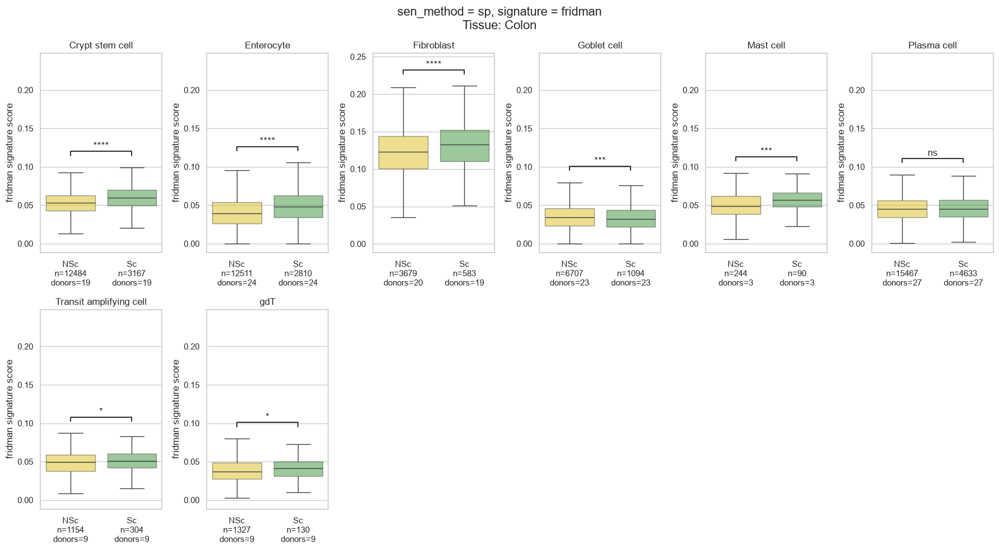

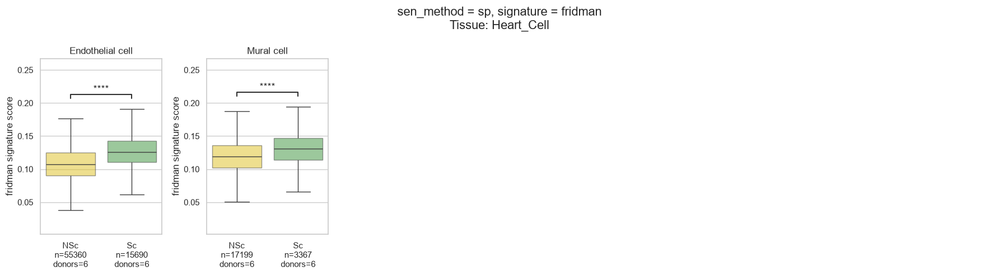

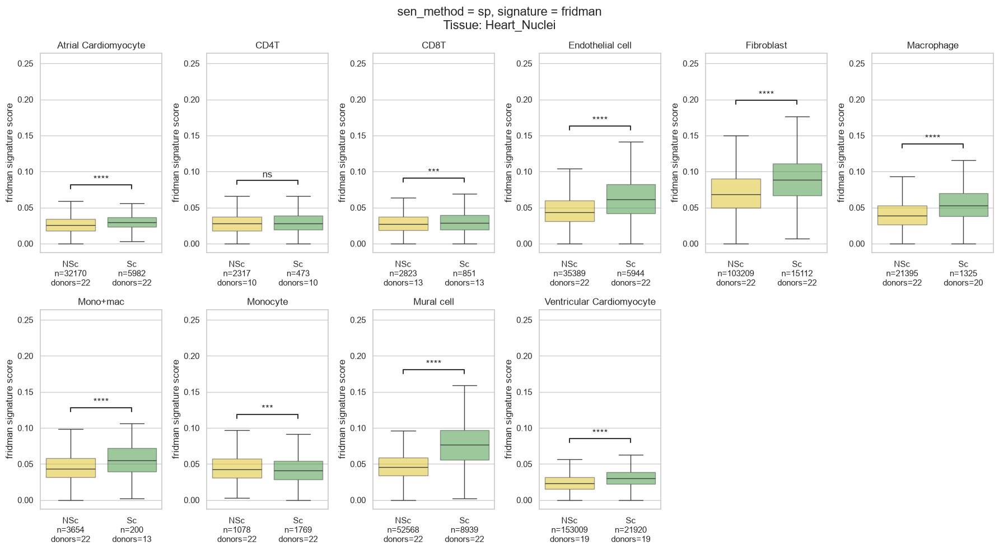

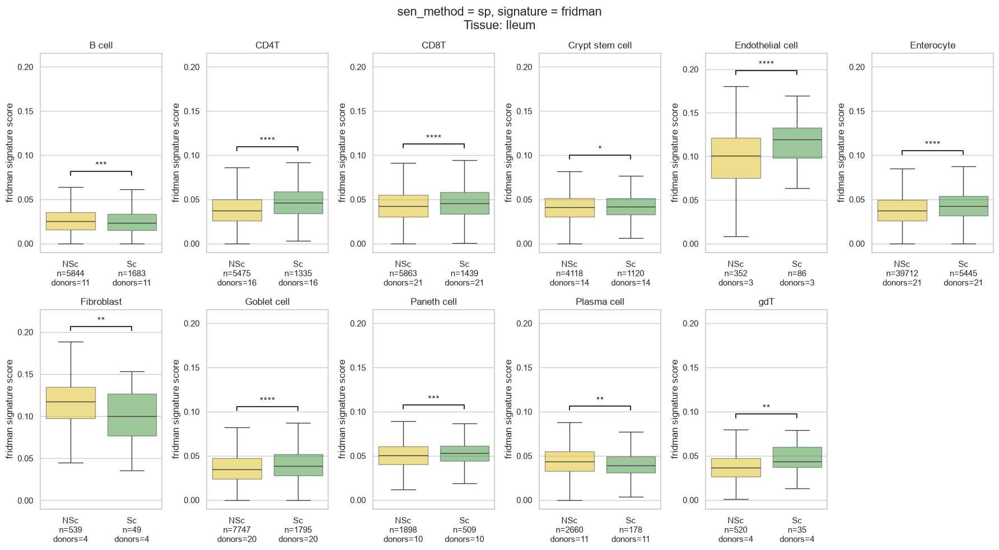

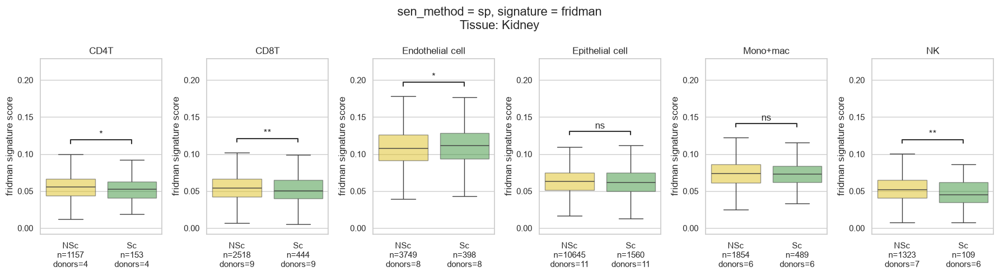

...

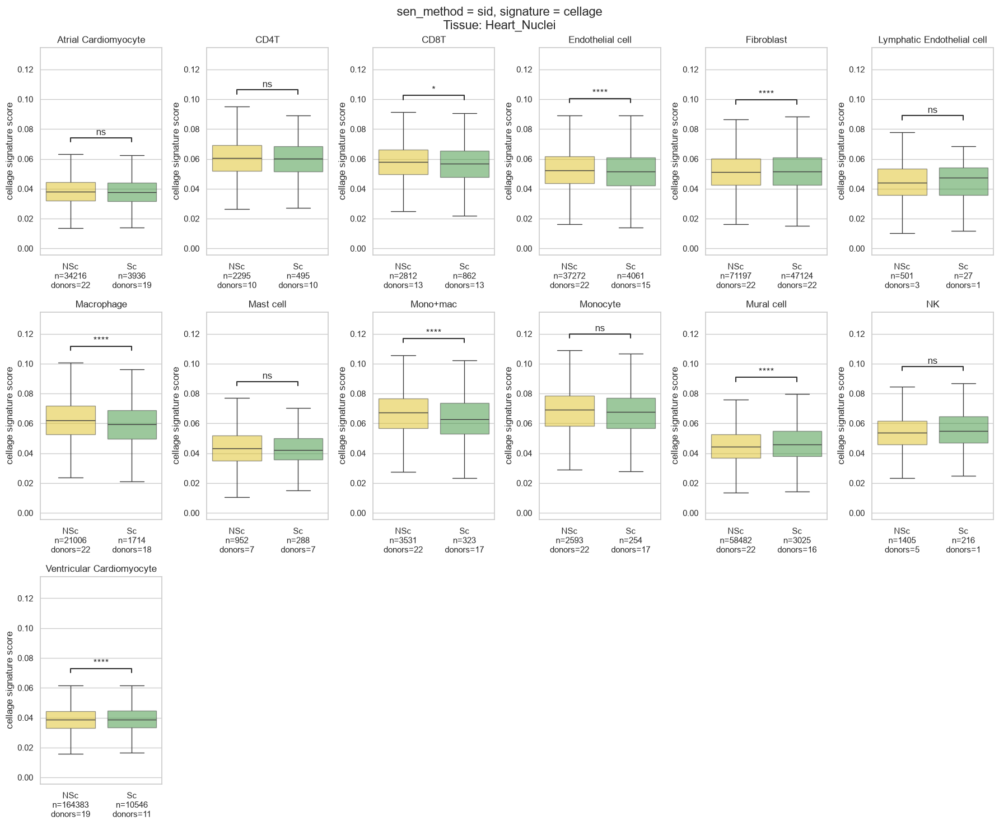

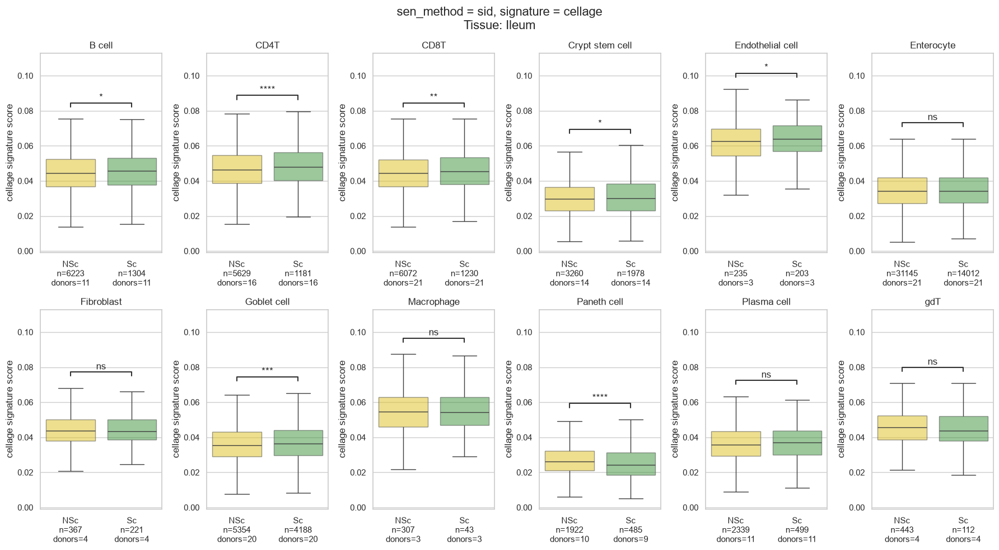

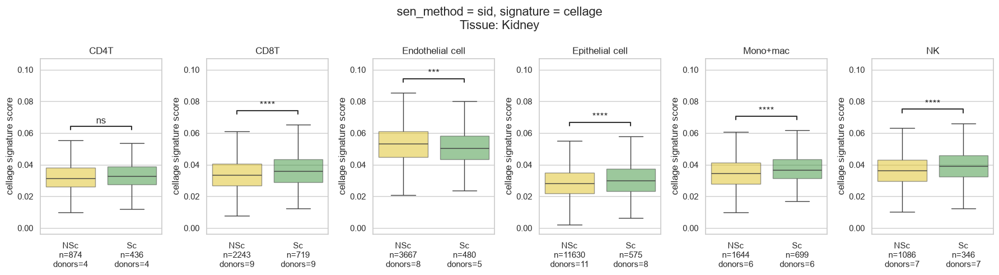

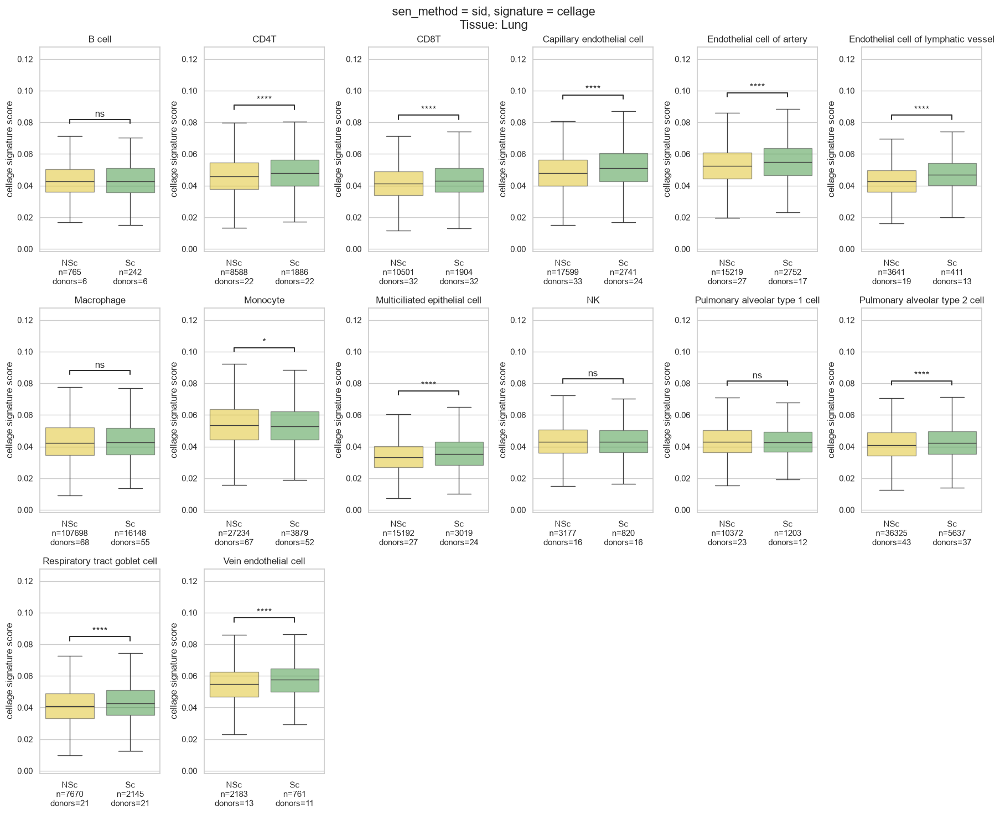

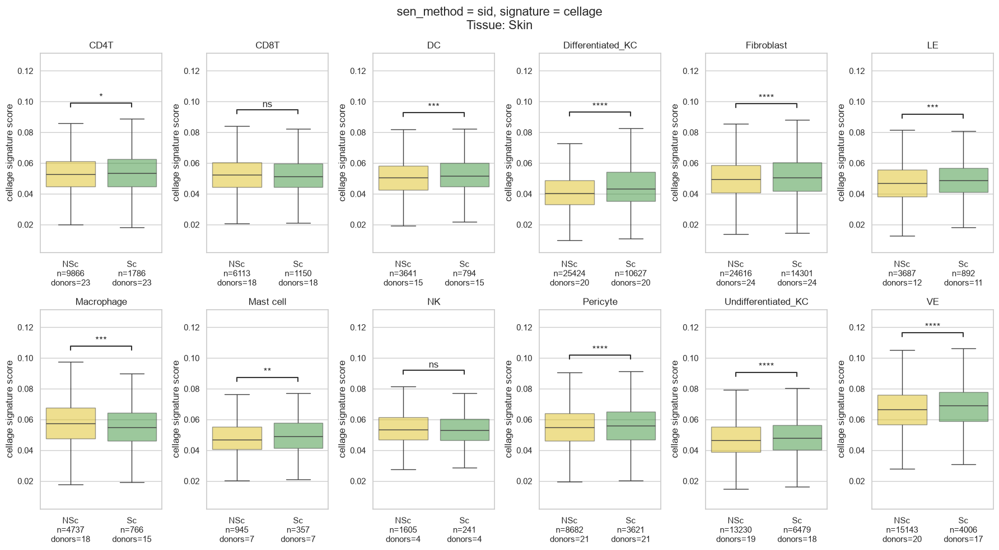

In [72]:
for m in methods:
    for s in sen_sigs:
        plot_senescence_boxplots_with_effect(obs, m, s)

In [8]:
print(obs.fridman.min(), obs.fridman.max())
print(obs.cellage.min(), obs.cellage.max())
print(obs.senmayo.min(), obs.senmayo.max())

0.0 0.2860926794329499
0.0011812600445127 0.1282858547912009
0.0 0.2028903225806451


In [9]:
# Missingness and observed ranges in auc scores
auc_info = pd.DataFrame(
    {
        "n_non_missing": obs[sen_sigs].notna().sum(),
        "n_missing": obs[sen_sigs].isna().sum(),
        "min": obs[sen_sigs].min(),
        "max": obs[sen_sigs].max(),
        "median": obs[sen_sigs].median(),
    }
)

auc_info

,n_non_missing,n_missing,min,max,median
fridman,1253024,0,0.000000,0.286093,0.061313
senmayo,1253024,0,0.000000,0.202890,0.041170
cellage,1253024,0,0.001181,0.128286,0.044143


In [10]:
"""2. Aggregate AUCell scores to donor level"""

donor_records = []

for method in methods:
    group_col = f"{method}_sen_group"

    # Keep only cells with a valid Sc/NSc classification
    valid_mask = obs[group_col].notna()

    df = obs.loc[
        valid_mask, ["GSM_id", "Tissue_global", "cell_type", group_col, *sen_sigs]
    ].copy()

    df = df.rename(columns={group_col: "sen_group"})

    for sig in sen_sigs:
        tmp = df[["GSM_id", "Tissue_global", "cell_type", "sen_group", sig]].dropna(
            subset=[sig]
        )

        # Median AUCell score across cells
        # within donor × tissue × cell type × senescence state
        agg = (
            tmp.groupby(
                ["GSM_id", "Tissue_global", "cell_type", "sen_group"], observed=True
            )[sig]
            .median()
            .reset_index()
        )

        agg["method"] = method
        agg["signature"] = sig
        agg["AUCell"] = agg[sig]

        agg = agg.drop(columns=[sig])

        donor_records.append(agg)


donor_auc = pd.concat(donor_records, ignore_index=True)

donor_auc.head()

,GSM_id,Tissue_global,cell_type,sen_group,method,signature,AUCell
0,A61,Heart_Nuclei,Atrial cardiomyocytes,NSc,sp,fridman,0.032839
1,A61,Heart_Nuclei,Atrial cardiomyocytes,Sc,sp,fridman,0.034177
2,A61,Heart_Nuclei,CD4 T cells,NSc,sp,fridman,0.027771
3,A61,Heart_Nuclei,CD4 T cells,Sc,sp,fridman,0.030650
4,A61,Heart_Nuclei,CD8 T cells,NSc,sp,fridman,0.029616


In [11]:
"""3. Create paired donor-level Sc vs NSc data"""

paired_records = []

for keys, group in donor_auc.groupby(
    ["method", "signature", "Tissue_global", "cell_type", "GSM_id"], observed=True
):
    method, signature, tissue, cell_type, donor = keys

    sc = group.loc[group["sen_group"] == "Sc", "AUCell"]

    nsc = group.loc[group["sen_group"] == "NSc", "AUCell"]

    # Keep only donors for which both Sc and NSc are available
    if len(sc) == 1 and len(nsc) == 1:
        paired_records.append(
            {
                "method": method,
                "signature": signature,
                "Tissue_global": tissue,
                "cell_type": cell_type,
                "GSM_id": donor,
                "AUCell_Sc": sc.iloc[0],
                "AUCell_NSc": nsc.iloc[0],
                "delta_AUCell": sc.iloc[0] - nsc.iloc[0],
            }
        )


paired_auc = pd.DataFrame(paired_records)

paired_auc.head()

# теперь каждая строка — donor-level paired observation

,method,signature,Tissue_global,cell_type,GSM_id,AUCell_Sc,AUCell_NSc,delta_AUCell
0,ds,cellage,Colon,B cells,GSM6614348,0.041364,0.038703,0.002662
1,ds,cellage,Colon,B cells,GSM6614350,0.043073,0.040221,0.002852
2,ds,cellage,Colon,B cells,GSM7307102,0.039025,0.037499,0.001526
3,ds,cellage,Colon,B cells,GSM7307103,0.039108,0.037734,0.001374
4,ds,cellage,Colon,B cells,GSM7307104,0.040822,0.037681,0.003141


In [12]:
"""def Rank-biserial correlation """


def rank_biserial_from_differences(differences):
    """
    Rank-biserial correlation for paired data.

    Positive values indicate that Sc tends to have
    higher values than NSc.
    """

    differences = np.asarray(differences, dtype=float)
    differences = differences[np.isfinite(differences)]

    # Remove zero differences
    differences = differences[differences != 0]

    if len(differences) == 0:
        return np.nan

    abs_diff = np.abs(differences)

    # Average ranks for ties
    ranks = rankdata(abs_diff, method="average")

    positive_rank_sum = ranks[differences > 0].sum()
    negative_rank_sum = ranks[differences < 0].sum()

    denominator = positive_rank_sum + negative_rank_sum

    if denominator == 0:
        return np.nan

    return (positive_rank_sum - negative_rank_sum) / denominator

Тест Вилкоксона отвечает, *есть ли систематическое различие Sc и NSc?*

RBC же про то, **насколько сильное это различие**

In [13]:
"""def Bootstrap 95% CI for rank-biserial correlation"""


def bootstrap_rbc_ci(differences, n_boot=10_000, random_state=42):
    """
    Percentile bootstrap 95% CI for rank-biserial correlation.
    Resampling is performed at the donor level.
    """
    differences = np.asarray(differences, dtype=float)
    differences = differences[np.isfinite(differences)]

    n = len(differences)

    if n < 2:
        return np.nan, np.nan

    rng = np.random.default_rng(random_state)

    boot_values = []

    for _ in range(n_boot):
        sample = rng.choice(differences, size=n, replace=True)

        rbc = rank_biserial_from_differences(sample)

        if np.isfinite(rbc):
            boot_values.append(rbc)

    if len(boot_values) == 0:
        return np.nan, np.nan

    ci_low, ci_high = np.percentile(boot_values, [2.5, 97.5])

    return ci_low, ci_high

In [14]:
"""4. Основной статистический анализ"""

results = []

analysis_groups = ["method", "signature", "Tissue_global", "cell_type"]

for keys, group in tqdm(paired_auc.groupby(analysis_groups, observed=True)):
    method, signature, tissue, cell_type = keys

    differences = group["delta_AUCell"].to_numpy()

    n = len(differences)

    # Wilcoxon signed-rank test
    if np.all(differences == 0):
        p_value = 1.0
        statistic = 0.0

    else:
        test = wilcoxon(
            differences, alternative="two-sided", zero_method="wilcox", method="auto"
        )

        statistic = test.statistic
        p_value = test.pvalue

    # Effect size
    rbc = rank_biserial_from_differences(differences)

    # Bootstrap CI
    ci_low, ci_high = bootstrap_rbc_ci(differences, n_boot=1000)

    # Directional consistency
    fraction_positive = np.mean(differences > 0)

    # Median delta
    median_delta = np.median(differences)

    results.append(
        {
            "method": method,
            "signature": signature,
            "Tissue_global": tissue,
            "cell_type": cell_type,
            "n_donors": n,
            "median_AUCell_delta": median_delta,
            "fraction_positive": fraction_positive,
            "wilcoxon_statistic": statistic,
            "p_value": p_value,
            "rank_biserial_r": rbc,
            "rbc_ci_low": ci_low,
            "rbc_ci_high": ci_high,
        }
    )

results_df = pd.DataFrame(results)

results_df.head()

  0%|                                                                                           | 0/603 [00:00<?, ?it/s]

100%|█████████████████████████████████████████████████████████████████████████████████| 603/603 [01:08<00:00,  8.84it/s]


,method,signature,Tissue_global,cell_type,n_donors,median_AUCell_delta,fraction_positive,wilcoxon_statistic,p_value,rank_biserial_r,rbc_ci_low,rbc_ci_high
0,ds,cellage,Colon,B cells,16,0.001451,0.875000,10.0,0.001312,0.852941,0.514706,1.000000
1,ds,cellage,Colon,CD4 T cells,23,-0.000162,0.434783,135.0,0.940555,0.021739,-0.478261,0.456522
2,ds,cellage,Colon,CD8 T cells,21,0.001493,0.666667,78.0,0.202917,0.324675,-0.177489,0.722944
3,ds,cellage,Colon,Crypt stem cells,19,-0.000570,0.473684,90.0,0.859573,-0.052632,-0.600000,0.452632
4,ds,cellage,Colon,Enterocytes,24,0.005630,0.916667,15.0,0.000016,0.900000,0.653333,1.000000


In [15]:
"""FDR correction within method × signature"""

results_df["FDR"] = np.nan

for (method, signature), idx in results_df.groupby(
    ["method", "signature"], observed=True
).groups.items():
    pvals = results_df.loc[idx, "p_value"]

    valid = pvals.notna()

    if valid.sum() == 0:
        continue

    _, pvals_fdr, _, _ = multipletests(pvals[valid], method="fdr_bh")

    valid_idx = pvals[valid].index

    results_df.loc[valid_idx, "FDR"] = pvals_fdr

In [16]:
def significance_label(fdr):
    if pd.isna(fdr):
        return ""
    elif fdr < 0.001:
        return "∗∗∗"
    elif fdr < 0.01:
        return "∗∗"
    elif fdr < 0.05:
        return "∗"
    else:
        return ""


results_df["significance"] = results_df["FDR"].apply(significance_label)

In [17]:
results_df = results_df[
    [
        "method",
        "signature",
        "Tissue_global",
        "cell_type",
        "n_donors",
        "median_AUCell_delta",
        "fraction_positive",
        "wilcoxon_statistic",
        "p_value",
        "FDR",
        "rank_biserial_r",
        "rbc_ci_low",
        "rbc_ci_high",
        "significance",
    ]
].sort_values(["method", "signature", "Tissue_global", "cell_type"])

results_df.head()

,method,signature,Tissue_global,cell_type,n_donors,median_AUCell_delta,fraction_positive,wilcoxon_statistic,p_value,FDR,rank_biserial_r,rbc_ci_low,rbc_ci_high,significance
0,ds,cellage,Colon,B cells,16,0.001451,0.875000,10.0,0.001312,0.005905,0.852941,0.514706,1.000000,∗∗
1,ds,cellage,Colon,CD4 T cells,23,-0.000162,0.434783,135.0,0.940555,1.000000,0.021739,-0.478261,0.456522,
2,ds,cellage,Colon,CD8 T cells,21,0.001493,0.666667,78.0,0.202917,0.332046,0.324675,-0.177489,0.722944,
3,ds,cellage,Colon,Crypt stem cells,19,-0.000570,0.473684,90.0,0.859573,0.969231,-0.052632,-0.600000,0.452632,
4,ds,cellage,Colon,Enterocytes,24,0.005630,0.916667,15.0,0.000016,0.000118,0.900000,0.653333,1.000000,∗∗∗


In [18]:
# Overall method performance

method_summary = (
    results_df.groupby(["method", "signature"], observed=True)
    .agg(
        median_RBC=("rank_biserial_r", "median"),
        mean_RBC=("rank_biserial_r", "mean"),
        median_delta=("median_AUCell_delta", "median"),
        median_fraction_positive=("fraction_positive", "median"),
        n_groups=("rank_biserial_r", "count"),
        n_significant=("FDR", lambda x: (x < 0.05).sum()),
    )
    .reset_index()
)

method_summary

,method,signature,median_RBC,mean_RBC,median_delta,median_fraction_positive,n_groups,n_significant
0,ds,cellage,0.583626,0.466829,0.001449,0.666667,72,22
1,ds,fridman,0.569048,0.429596,0.002759,0.695602,72,27
2,ds,senmayo,0.814286,0.506206,0.003456,0.840909,72,35
3,sid,cellage,0.552670,0.480745,0.001002,0.716518,72,21
4,sid,fridman,0.005495,0.032864,0.000145,0.500000,72,7
5,sid,senmayo,0.183766,0.177924,0.000375,0.585784,72,7
6,sp,cellage,0.000000,0.080221,-0.000115,0.500000,57,18
7,sp,fridman,0.600000,0.438380,0.003429,0.666667,57,27
8,sp,senmayo,0.552381,0.422635,0.001873,0.727273,57,25


### viz

In [ ]:
"""Основная визуализация — единый heatmap RBC
все signatures × methods на одной фигуре"""

# ============================================================
# ROW ORDER
# Sort tissue × cell type by mean RBC
# across all methods and signatures
# ============================================================
row_order = (
    results_df.groupby(["Tissue_global", "cell_type"], observed=True)["rank_biserial_r"]
    .mean()
    .sort_values(ascending=False)
    .index
)
row_order = [f"{tissue} | {cell_type}" for tissue, cell_type in row_order]


# PREPARE DATA
# columns = signature × method
heatmap_list = []

for sig in sen_sigs:
    df = results_df[results_df["signature"] == sig].copy()
    df["group"] = df["Tissue_global"].astype(str) + " | " + df["cell_type"].astype(str)

    # rows = tissue × cell type
    # columns = methods
    heatmap_data = df.pivot(index="group", columns="method", values="rank_biserial_r")
    heatmap_data = heatmap_data.reindex(columns=methods)

    # Add signature to column names
    heatmap_data.columns = [f"{sig} | {method}" for method in heatmap_data.columns]
    heatmap_list.append(heatmap_data)


# Combine all signatures horizontally
heatmap_data = pd.concat(heatmap_list, axis=1)

# Apply common row order
available_rows = [group for group in row_order if group in heatmap_data.index]
heatmap_data = heatmap_data.reindex(available_rows)


# FIGURE
fig, ax = plt.subplots(figsize=(18, 18))

sns.heatmap(
    heatmap_data,
    ax=ax,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    linecolor="white",
    annot=False,
    cbar=True,
    cbar_kws={
        "label": "Rank-biserial correlation",
        "pad": 0.03,
        "shrink": 0.95,
    },
    yticklabels=True,
)

# Y AXIS
ax.set_yticks(np.arange(len(heatmap_data.index)) + 0.5)
ax.set_yticklabels(heatmap_data.index, rotation=0, fontsize=16, fontweight="semibold")
ax.set_ylabel("Tissue | cell type", fontsize=20, labelpad=12)

# X AXIS — METHODS
ax.set_xticks(np.arange(len(heatmap_data.columns)) + 0.5)
ax.set_xticklabels(
    methods * len(sen_sigs), rotation=0, fontsize=20, fontweight="semibold"
)
ax.set_xlabel("Senescence detection method", fontsize=22, labelpad=15)

# MISSING VALUES
for row_idx in range(len(heatmap_data.index)):
    for col_idx in range(len(heatmap_data.columns)):
        if pd.isna(heatmap_data.iloc[row_idx, col_idx]):
            ax.text(
                col_idx + 0.5,
                row_idx + 0.5,
                "—",
                ha="center",
                va="center",
                fontsize=18,
                # fontweight="bold",
            )

# SIGNIFICANCE ANNOTATIONS
for col_idx, column in enumerate(heatmap_data.columns):
    # Parse signature and method
    sig, method = column.split(" | ", 1)
    df = results_df[results_df["signature"] == sig].copy()
    df["group"] = df["Tissue_global"].astype(str) + " | " + df["cell_type"].astype(str)

    for row_idx, group_name in enumerate(heatmap_data.index):
        row = df[(df["group"] == group_name) & (df["method"] == method)]

        if row.empty:
            continue

        label = row["significance"].iloc[0]

        if pd.notna(label) and label != "":
            ax.text(
                col_idx + 0.5,
                row_idx + 0.5,
                label,
                ha="center",
                va="center",
                fontsize=18,
                fontweight="bold",
            )

# SIGNATURE LABELS
n_methods = len(methods)

for i, sig in enumerate(sen_sigs):
    start = i * n_methods
    end = (i + 1) * n_methods
    center = (start + end) / 2

    ax.text(
        center,
        1,
        sig,
        transform=ax.get_xaxis_transform(),
        ha="center",
        va="bottom",
        fontsize=22,
        fontweight="bold",
    )


# SEPARATORS BETWEEN SIGNATURES
# Make these even more prominent
for i in range(1, len(sen_sigs)):
    x = i * n_methods
    ax.axvline(x, color="black", linewidth=4, zorder=11)

# COLORBAR
cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=18)
cbar.set_label("Rank-biserial correlation", fontsize=20, labelpad=12)

# FINAL LAYOUT
fig.subplots_adjust(top=0.93, bottom=0.08, left=0.27, right=0.92)
plt.show()

☝☝☝

Цвет показывает силу эффекта

Звёздочка показывает FDR.

In [ ]:
"""Основная визуализация — единый heatmap RBC
все methods × signatures на одной фигуре"""

# ROW ORDER
# Sort tissue × cell type by mean RBC
# across all methods and signatures
# ============================================================
row_order = (
    results_df.groupby(["Tissue_global", "cell_type"], observed=True)["rank_biserial_r"]
    .mean()
    .sort_values(ascending=False)
    .index
)
row_order = [f"{tissue} | {cell_type}" for tissue, cell_type in row_order]

# PREPARE DATA
# columns = method × signature
heatmap_list = []

for method in methods:
    df = results_df[results_df["method"] == method].copy()
    df["group"] = df["Tissue_global"].astype(str) + " | " + df["cell_type"].astype(str)

    # rows = tissue × cell type
    # columns = signatures

    heatmap_data = df.pivot(
        index="group", columns="signature", values="rank_biserial_r"
    )

    heatmap_data = heatmap_data.reindex(columns=sen_sigs)

    # Add method to column names
    heatmap_data.columns = [
        f"{method} | {signature}" for signature in heatmap_data.columns
    ]

    heatmap_list.append(heatmap_data)

# Combine all methods horizontally
heatmap_data = pd.concat(heatmap_list, axis=1)

# Apply common row order
available_rows = [group for group in row_order if group in heatmap_data.index]

heatmap_data = heatmap_data.reindex(available_rows)

# FIGURE
fig, ax = plt.subplots(figsize=(18, 18), dpi=300)

sns.heatmap(
    heatmap_data,
    ax=ax,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    linecolor="white",
    annot=False,
    cbar=True,
    cbar_kws={
        "label": "Rank-biserial correlation",
        "pad": 0.03,
        "shrink": 0.95,
    },
    yticklabels=True,
)

# Y AXIS
ax.set_yticks(np.arange(len(heatmap_data.index)) + 0.5)
ax.set_yticklabels(heatmap_data.index, rotation=0, fontsize=17, fontweight="semibold")
ax.set_ylabel("Tissue | cell type", fontsize=20, labelpad=12)

# X AXIS — SIGNATURES
ax.set_xticks(np.arange(len(heatmap_data.columns)) + 0.5)
ax.set_xticklabels(
    sen_sigs * len(methods), rotation=0, fontsize=15, fontweight="semibold"
)
ax.set_xlabel("Universal senescence signature", fontsize=22, labelpad=15)

# MISSING VALUES
for row_idx in range(len(heatmap_data.index)):
    for col_idx in range(len(heatmap_data.columns)):
        if pd.isna(heatmap_data.iloc[row_idx, col_idx]):
            ax.text(
                col_idx + 0.5,
                row_idx + 0.5,
                "—",
                ha="center",
                va="center",
                fontsize=18,
                # fontweight="bold",
            )

# SIGNIFICANCE ANNOTATIONS
for col_idx, column in enumerate(heatmap_data.columns):
    # Parse method and signature
    method, signature = column.split(" | ", 1)

    df = results_df[results_df["method"] == method].copy()

    df["group"] = df["Tissue_global"].astype(str) + " | " + df["cell_type"].astype(str)

    for row_idx, group_name in enumerate(heatmap_data.index):
        row = df[(df["group"] == group_name) & (df["signature"] == signature)]

        if row.empty:
            continue

        label = row["significance"].iloc[0]

        if pd.notna(label) and label != "":
            ax.text(
                col_idx + 0.5,
                row_idx + 0.5,
                label,
                ha="center",
                va="center",
                fontsize=18,
                fontweight="bold",
            )

# METHOD LABELS
n_signatures = len(sen_sigs)

for i, method in enumerate(methods):
    start = i * n_signatures
    end = (i + 1) * n_signatures
    center = (start + end) / 2

    ax.text(
        center,
        1,
        method,
        transform=ax.get_xaxis_transform(),
        ha="center",
        va="bottom",
        fontsize=22,
        fontweight="bold",
    )

# SEPARATORS BETWEEN METHODS
for i in range(1, len(methods)):
    x = i * n_signatures
    ax.axvline(x, color="black", linewidth=4, zorder=11)

# COLORBAR
cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=18)
cbar.set_label("Rank-biserial correlation", fontsize=20, labelpad=12)

# FINAL LAYOUT
fig.subplots_adjust(top=0.93, bottom=0.08, left=0.27, right=0.92)
plt.show()

In [ ]:
"""Heatmap of median ΔAUCell for all methods × signatures"""

# ============================================================
# ROW ORDER
# Sort tissue × cell type by mean ΔAUCell
# across all methods and signatures
row_order = (
    results_df.groupby(["Tissue_global", "cell_type"], observed=True)[
        "median_AUCell_delta"
    ]
    .mean()
    .sort_values(ascending=False)
    .index
)

row_order = [f"{tissue} | {cell_type}" for tissue, cell_type in row_order]

# PREPARE DATA
# columns = method × signature
heatmap_list = []

for method in methods:
    df = results_df[results_df["method"] == method].copy()
    df["group"] = df["Tissue_global"].astype(str) + " | " + df["cell_type"].astype(str)
    # rows = tissue × cell type
    # columns = signatures
    heatmap_data = df.pivot(
        index="group", columns="signature", values="median_AUCell_delta"
    )
    heatmap_data = heatmap_data.reindex(columns=sen_sigs)
    # Add method to column names
    heatmap_data.columns = [
        f"{method} | {signature}" for signature in heatmap_data.columns
    ]
    heatmap_list.append(heatmap_data)

# Combine all methods horizontally
heatmap_data = pd.concat(heatmap_list, axis=1)
# Apply common row order
available_rows = [group for group in row_order if group in heatmap_data.index]
heatmap_data = heatmap_data.reindex(available_rows)

# COLOR SCALE
# One symmetric scale for the entire heatmap
max_abs = np.nanmax(np.abs(heatmap_data.values))

# FIGURE
fig, ax = plt.subplots(figsize=(20, 18), dpi=300)

sns.heatmap(
    heatmap_data,
    ax=ax,
    cmap="coolwarm",
    center=0,
    vmin=-max_abs,
    vmax=max_abs,
    linewidths=0.5,
    linecolor="white",
    annot=False,
    cbar=True,
    cbar_kws={
        "label": "Median ΔAUCell (Sc − NSc)",
        "pad": 0.03,
        "shrink": 0.95,
    },
    yticklabels=True,
)

# MISSING VALUES
for row_idx in range(len(heatmap_data.index)):
    for col_idx in range(len(heatmap_data.columns)):
        if pd.isna(heatmap_data.iloc[row_idx, col_idx]):
            ax.text(
                col_idx + 0.5,
                row_idx + 0.5,
                "—",
                ha="center",
                va="center",
                fontsize=18,
                fontweight="bold",
            )

# Y AXIS
ax.set_yticks(np.arange(len(heatmap_data.index)) + 0.5)
ax.set_yticklabels(heatmap_data.index, rotation=0, fontsize=17, fontweight="semibold")
ax.set_ylabel("Tissue | cell type", fontsize=20, labelpad=12)

# X AXIS — SIGNATURES
ax.set_xticks(np.arange(len(heatmap_data.columns)) + 0.5)
ax.set_xticklabels(
    sen_sigs * len(methods), rotation=0, fontsize=16, fontweight="semibold"
)
ax.set_xlabel("Universal senescence signature", fontsize=22, labelpad=15)

# METHOD LABELS
n_signatures = len(sen_sigs)
for i, method in enumerate(methods):
    start = i * n_signatures
    end = (i + 1) * n_signatures
    center = (start + end) / 2
    ax.text(
        center,
        1,
        method,
        transform=ax.get_xaxis_transform(),
        ha="center",
        va="bottom",
        fontsize=22,
        fontweight="bold",
    )

# SEPARATORS BETWEEN METHODS
for i in range(1, len(methods)):
    x = i * n_signatures
    ax.axvline(x, color="black", linewidth=4, zorder=11)

# COLORBAR
cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=18)
cbar.set_label("Median ΔAUCell (Sc − NSc)", fontsize=20, labelpad=12)

# FINAL LAYOUT
fig.subplots_adjust(top=0.93, bottom=0.08, left=0.27, right=0.92)

plt.show()

In [ ]:
import matplotlib.cm as cm


def plot_paired_rbc_all_signatures(
    results_df,
    signatures,
    methods,
    color_dict,
    figsize=(16, 9),
    alpha_lines=0.4,
    jitter_width=0.1,
):
    """
    Одна общая фигура для нескольких сигнатур.

    Для каждой комбинации Tissue_global × cell_type
    точки разных методов соединяются одной линией.

    Цвет определяется только cell_type.
    """

    # Подготовка данных
    df = results_df[results_df["signature"].isin(signatures)].copy()
    df["group"] = df["Tissue_global"].astype(str) + " | " + df["cell_type"].astype(str)

    # Оставляем только Tissue × cell_type,
    # где присутствуют минимум 2 метода
    counts = df.groupby(["signature", "group"])["method"].nunique()
    valid_groups = counts[counts >= 2].index
    df = df.set_index(["signature", "group"])
    df = df.loc[df.index.isin(valid_groups)].reset_index()

    # Параметры расположения блоков
    n_methods = len(methods)
    # Расстояние между соседними методами
    method_spacing = 0.8
    # Дополнительное расстояние между сигнатурами
    signature_gap = 0.5
    # Позиции методов внутри одного блока
    method_positions = np.arange(n_methods) * method_spacing
    # Начальные позиции блоков сигнатур
    block_width = (n_methods - 1) * method_spacing

    signature_starts = [
        i * (block_width + signature_gap) for i in range(len(signatures))
    ]

    # Полные X-позиции методов
    x_positions = {}

    for sig, start in zip(signatures, signature_starts):
        x_positions[sig] = {
            method: start + method_positions[i] for i, method in enumerate(methods)
        }

    # Figure
    fig, ax = plt.subplots(figsize=figsize, dpi=300)
    rng = np.random.default_rng(seed=42)

    # Отрисовка линий и точек
    for sig in signatures:
        sig_df = df[df["signature"] == sig]
        group_order = sorted(sig_df["group"].unique())

        for group in group_order:
            group_df = sig_df[sig_df["group"] == group]
            available = set(group_df["method"])

            # Цвет определяется только cell_type
            cell_type = group_df["cell_type"].iloc[0]
            current_color = color_dict.get(cell_type, "gray")

            # Один jitter для всей линии,
            # поэтому точки одной Tissue × cell_type остаются
            # точно над своей линией
            jitter = rng.uniform(-jitter_width, jitter_width)

            # Линия между методами
            if len(available) >= 2:
                ordered = group_df.set_index("method").reindex(methods)

                x_values = [
                    x_positions[sig][m] + jitter for m in methods if m in available
                ]

                y_values = [
                    ordered.loc[m, "rank_biserial_r"] for m in methods if m in available
                ]

                ax.plot(
                    x_values,
                    y_values,
                    linewidth=1.8,
                    alpha=alpha_lines,
                    color=current_color,
                    zorder=2,
                )

            # Точки
            for method in methods:
                row = group_df[group_df["method"] == method]

                if len(row) == 0:
                    continue

                value = row["rank_biserial_r"].iloc[0]

                ax.scatter(
                    x_positions[sig][method] + jitter,
                    value,
                    s=80,
                    color=current_color,
                    alpha=0.65,
                    zorder=3,
                )

    # Нулевая линия
    ax.axhline(
        0,
        linestyle="--",
        linewidth=1.2,
        color="black",
        alpha=0.5,
        zorder=1,
    )

    # X-axis
    all_x = []
    for sig in signatures:
        for method in methods:
            all_x.append(x_positions[sig][method])

    ax.set_xticks(all_x)
    ax.set_xticklabels(
        methods * len(signatures),
        fontsize=16,
        fontweight="semibold",
    )

    ax.set_xlabel(
        "Senescence detection method\n",
        fontsize=18,
        # fontweight="semibold",
        labelpad=12,
    )

    # Подписи сигнатур над каждым блоком
    for sig, start in zip(signatures, signature_starts):
        center = start + block_width / 2

        ax.text(
            center,
            1.0,
            sig,
            transform=ax.get_xaxis_transform(),
            ha="center",
            va="bottom",
            fontsize=18,
            fontweight="semibold",
        )

    # ============================================================
    # Y-axis
    # ============================================================

    ax.set_ylabel(
        "Rank-biserial correlation",
        fontsize=18,
        # fontweight="semibold",
    )

    ax.set_ylim(-1.05, 1.05)
    ax.tick_params(
        axis="y",
        labelsize=13,
    )
    ax.tick_params(
        axis="x",
        length=0,
        pad=8,
    )

    # Немного воздуха между блоками
    ax.set_xlim(
        min(all_x) - 0.2,
        max(all_x) + 0.2,
    )

    # Убираем верхнюю и правую рамки
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.grid(
        axis="y",
        alpha=0.2,
        linewidth=0.8,
    )

    plt.tight_layout()

    return fig, ax


def add_cell_type_legend(fig, color_dict, ncol=5):
    """помещает легенду под основным графиком"""
    legend_elements = [
        plt.Line2D(
            [0],
            [0],
            marker="o",
            color="w",
            markerfacecolor=color,
            markersize=9,
            label=cell_type,
        )
        for cell_type, color in color_dict.items()
    ]

    fig.legend(
        handles=legend_elements,
        loc="lower center",
        bbox_to_anchor=(0.55, -0.12),
        ncol=ncol,
        frameon=False,
        fontsize=12,
        title="\nCell Types",
        title_fontsize=15,
    )

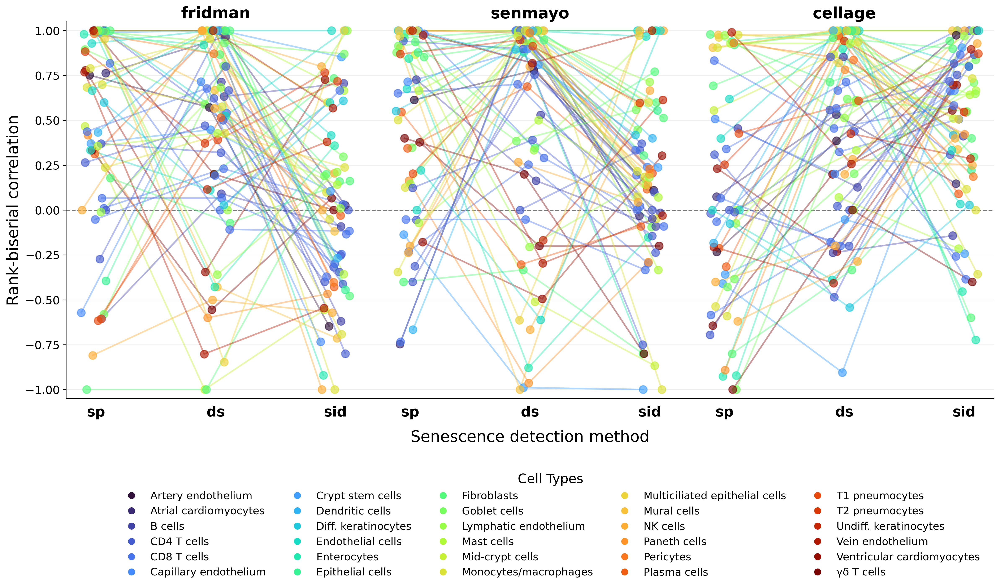

In [ ]:
# Все cell types
all_cell_types = sorted(results_df["cell_type"].dropna().unique())

# Цвета cell types
colors = cm.turbo(np.linspace(0, 1, len(all_cell_types)))

color_dict = dict(zip(all_cell_types, colors))

# ============================================================
# Одна общая фигура
# ============================================================

fig, ax = plot_paired_rbc_all_signatures(
    results_df=results_df,
    signatures=sen_sigs,
    methods=methods,
    color_dict=color_dict,
    figsize=(16, 10),
)

# Легенда снизу
add_cell_type_legend(
    fig,
    color_dict,
    ncol=5,
)

# Оставляем место под легенду
plt.subplots_adjust(
    bottom=0.18,
    top=0.78,
)

plt.show()

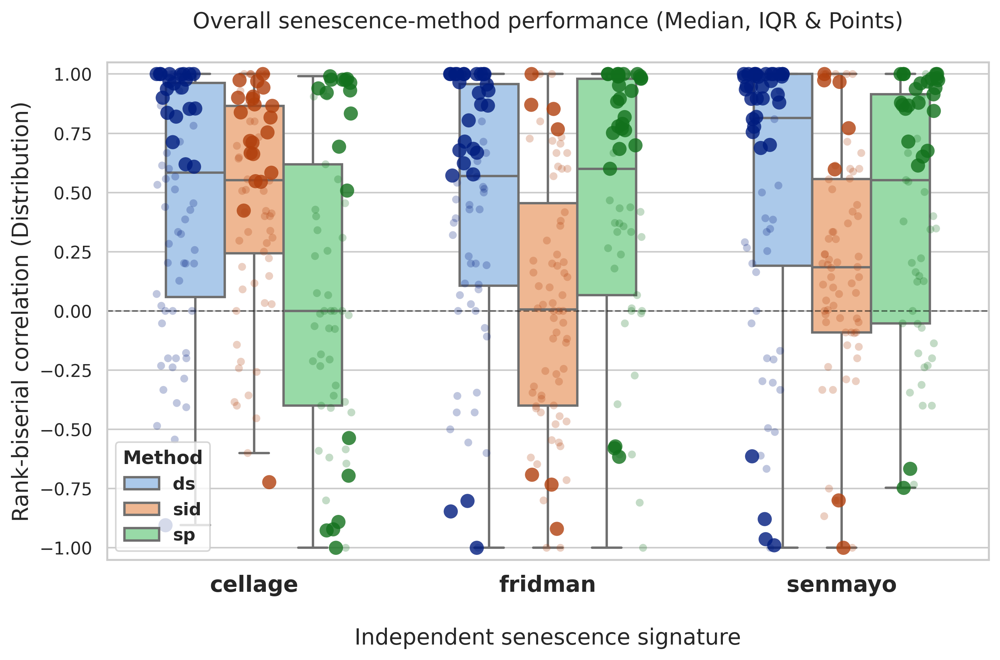

In [ ]:
"""Method ranking across signatures
(median, IQR, 1.5xIQR, values)"""

# Настраиваем стиль, чтобы графики выглядели аккуратно
sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(9, 6), dpi=300)

# 1. Строим "коробочки" (медиана, IQR, усы), имитирующие барплоты
# Передаем исходный results_df, чтобы seaborn сам посчитал квартили
sns.boxplot(
    data=results_df,
    x="signature",
    y="rank_biserial_r",
    hue="method",
    palette="pastel",  # Мягкие цвета для подложки-коробок
    width=0.6,  # Ширина столбцов-коробок
    fliersize=0,  # Прячем стандартные точки-выбросы (их нарисует stripplot ниже)
    linewidth=1.5,  # Толщина границ
    ax=ax,
)

significant = results_df["significance"] != ""

sns.stripplot(
    data=results_df[~significant],
    x="signature",
    y="rank_biserial_r",
    hue="method",
    palette="dark",
    size=5,
    alpha=0.25,
    dodge=True,
    jitter=0.2,
    legend=False,
    ax=ax,
)

sns.stripplot(
    data=results_df[significant],
    x="signature",
    y="rank_biserial_r",
    hue="method",
    palette="dark",
    size=9,
    alpha=0.8,
    dodge=True,
    jitter=0.2,
    legend=False,
    ax=ax,
)

# Нулевая линия
ax.axhline(0, linestyle="--", linewidth=1, color="black", alpha=0.5)

# Оформление осей и заголовков
ax.set_ylabel("Rank-biserial correlation (Distribution)", fontsize=14)
ax.set_xlabel(f"\nIndependent senescence signature", fontsize=14)
ax.set_title(
    "Overall senescence-method performance (Median, IQR & Points)\n", fontsize=14
)
# ax.tick_params(axis='x', labelfont={'weight': 'semibold', 'size': 14})
for label in ax.get_xticklabels():
    label.set_fontweight("semibold")
    label.set_fontsize(14)

# Ограничиваем ось Y под масштаб корреляции
ax.set_ylim(-1.05, 1.05)

# Настройка легенды (чтобы не было дублирования из-за hue)
handles, labels = ax.get_legend_handles_labels()
# Берем только первую половину хэндлов (они относятся к boxplot)
ax.legend(
    handles[: len(results_df["method"].unique())],
    labels[: len(results_df["method"].unique())],
    title="Method",
    loc="lower left",
    prop={"weight": "semibold"},  # Делает полужирным текст элементов
    title_fontproperties={"weight": "semibold"},  # Делает полужирным заголовок "Method"
)

plt.tight_layout()
plt.show()


### Анализ RBC метриками конкордантности

In [23]:
from sklearn.metrics import cohen_kappa_score, matthews_corrcoef
from statsmodels.stats.inter_rater import fleiss_kappa

In [24]:
"""RBC values for the same `tissue × cell type × signature` across methods"""

rbc_wide = results_df.pivot_table(
    index=["signature", "Tissue_global", "cell_type"],
    columns="method",
    values=["rank_biserial_r", "p_value", "FDR"],
    aggfunc="first",
)

# Flatten MultiIndex columns
rbc_wide.columns = [f"{value}_{method}" for value, method in rbc_wide.columns]

rbc_wide = rbc_wide.reset_index()

display(rbc_wide.shape)
rbc_wide.head()

(216, 12)

,signature,Tissue_global,cell_type,FDR_ds,FDR_sid,FDR_sp,p_value_ds,p_value_sid,p_value_sp,rank_biserial_r_ds,rank_biserial_r_sid,rank_biserial_r_sp
0,cellage,Colon,B cells,0.005905,0.336828,NaN,0.001312,0.159058,NaN,0.852941,0.411765,NaN
1,cellage,Colon,CD4 T cells,1.000000,0.008738,NaN,0.940555,0.000849,NaN,0.021739,0.753623,NaN
2,cellage,Colon,CD8 T cells,0.332046,0.097734,NaN,0.202917,0.042080,NaN,0.324675,0.506494,NaN
3,cellage,Colon,Crypt stem cells,0.969231,0.507527,0.314132,0.859573,0.373596,0.181866,-0.052632,-0.242105,-0.357895
4,cellage,Colon,Enterocytes,0.000118,0.118442,0.000055,0.000016,0.052641,0.000007,0.900000,-0.453333,-0.926667


In [25]:
"""RBC direction"""

for method in methods:
    rbc_wide[f"direction_{method}"] = np.sign(rbc_wide[f"rank_biserial_r_{method}"])

    # RBC = 0 → направление не определено
    rbc_wide.loc[rbc_wide[f"rank_biserial_r_{method}"] == 0, f"direction_{method}"] = (
        np.nan
    )


"""Significance"""

for method in methods:
    rbc_wide[f"significant_{method}"] = rbc_wide[f"FDR_{method}"] < 0.05

In [26]:
"""Group-level (signature × Tissue × cell_type) agreement"""

agreement_df = rbc_wide[
    [
        "signature",
        "Tissue_global",
        "cell_type",
        "direction_sp",
        "direction_sid",
        "direction_ds",
        "significant_sp",
        "significant_sid",
        "significant_ds",
    ]
].copy()

In [27]:
"""Pairwise agreement"""

agreement_df["agreement_sp_sid"] = np.where(
    agreement_df["direction_sp"].notna() & agreement_df["direction_sid"].notna(),
    (agreement_df["direction_sp"] == agreement_df["direction_sid"]).astype(int),
    np.nan,
)

agreement_df["agreement_sp_ds"] = np.where(
    agreement_df["direction_sp"].notna() & agreement_df["direction_ds"].notna(),
    (agreement_df["direction_sp"] == agreement_df["direction_ds"]).astype(int),
    np.nan,
)

agreement_df["agreement_sid_ds"] = np.where(
    agreement_df["direction_sid"].notna() & agreement_df["direction_ds"].notna(),
    (agreement_df["direction_sid"] == agreement_df["direction_ds"]).astype(int),
    np.nan,
)


"""Agreement for all 3"""

agreement_df["agreement_all3"] = np.where(
    agreement_df[["direction_sp", "direction_sid", "direction_ds"]].notna().all(axis=1),
    (
        (agreement_df["direction_sp"] == agreement_df["direction_sid"])
        & (agreement_df["direction_sp"] == agreement_df["direction_ds"])
    ).astype(int),
    np.nan,
)

# agreement_df — основной group-level датафрейм

In [28]:
"""Significant group-level agreement"""

agreement_sig_df = agreement_df.copy()

agreement_sig_df["agreement_sp_sid"] = np.where(
    agreement_sig_df["significant_sp"]
    & agreement_sig_df["significant_sid"]
    & agreement_sig_df["direction_sp"].notna()
    & agreement_sig_df["direction_sid"].notna(),
    (agreement_sig_df["direction_sp"] == agreement_sig_df["direction_sid"]).astype(int),
    np.nan,
)

agreement_sig_df["agreement_sp_ds"] = np.where(
    agreement_sig_df["significant_sp"]
    & agreement_sig_df["significant_ds"]
    & agreement_sig_df["direction_sp"].notna()
    & agreement_sig_df["direction_ds"].notna(),
    (agreement_sig_df["direction_sp"] == agreement_sig_df["direction_ds"]).astype(int),
    np.nan,
)

agreement_sig_df["agreement_sid_ds"] = np.where(
    agreement_sig_df["significant_sid"]
    & agreement_sig_df["significant_ds"]
    & agreement_sig_df["direction_sid"].notna()
    & agreement_sig_df["direction_ds"].notna(),
    (agreement_sig_df["direction_sid"] == agreement_sig_df["direction_ds"]).astype(int),
    np.nan,
)

agreement_sig_df["agreement_all3"] = np.where(
    agreement_sig_df["significant_sp"]
    & agreement_sig_df["significant_sid"]
    & agreement_sig_df["significant_ds"]
    & agreement_sig_df[["direction_sp", "direction_sid", "direction_ds"]]
    .notna()
    .all(axis=1),
    (
        (agreement_sig_df["direction_sp"] == agreement_sig_df["direction_sid"])
        & (agreement_sig_df["direction_sp"] == agreement_sig_df["direction_ds"])
    ).astype(int),
    np.nan,
)


# agreement_sig_df - такой же group-lvl датафрейм согласованностей, но с фильтром по FDR

In [29]:
def calculate_pairwise_metrics(df, method1, method2, agreement_col):
    """Calculate aggregate agreement metrics for one method pair."""

    mask = df[f"direction_{method1}"].notna() & df[f"direction_{method2}"].notna()

    sub = df.loc[
        mask,
        [
            "signature",
            f"direction_{method1}",
            f"direction_{method2}",
        ],
    ].copy()

    if len(sub) == 0:
        return None

    y1 = sub[f"direction_{method1}"].astype(int)
    y2 = sub[f"direction_{method2}"].astype(int)

    # Percent agreement
    percent_agreement = np.mean(y1 == y2) * 100

    # Cohen's kappa
    kappa = cohen_kappa_score(y1, y2)

    # Jaccard для положительного направления
    positive_1 = y1 == 1
    positive_2 = y2 == 1

    intersection = (positive_1 & positive_2).sum()
    union = (positive_1 | positive_2).sum()

    jaccard = intersection / union if union > 0 else np.nan

    # MCC
    if y1.nunique() > 1 and y2.nunique() > 1:
        mcc = matthews_corrcoef(y1, y2)
    else:
        mcc = np.nan

    return {
        "signature": sub["signature"].iloc[0],
        "method_pair": f"{method1}–{method2}",
        "n_groups": len(sub),
        "n_concordant": np.sum(y1 == y2),
        "percent_agreement": percent_agreement,
        "cohen_kappa": kappa,
        "jaccard_positive": jaccard,
        "MCC": mcc,
    }

In [30]:
""" применение функции выше для каждой сен.сигнатуры"""

pair_results = []

for signature in agreement_df["signature"].dropna().unique():
    df_sig = agreement_df[agreement_df["signature"] == signature].copy()

    for method1, method2, agreement_col in [
        ("sp", "sid", "agreement_sp_sid"),
        ("sp", "ds", "agreement_sp_ds"),
        ("sid", "ds", "agreement_sid_ds"),
    ]:
        result = calculate_pairwise_metrics(df_sig, method1, method2, agreement_col)

        if result is not None:
            pair_results.append(result)

pair_metrics_df = pd.DataFrame(pair_results)

pair_metrics_df

,signature,method_pair,n_groups,n_concordant,percent_agreement,cohen_kappa,jaccard_positive,MCC
0,cellage,sp–sid,53,29,54.716981,0.106742,0.500000,0.159852
1,cellage,sp–ds,52,31,59.615385,0.192308,0.522727,0.235441
2,cellage,sid–ds,68,49,72.058824,0.015244,0.712121,0.015783
3,fridman,sp–sid,54,31,57.407407,0.129032,0.510638,0.156780
4,fridman,sp–ds,55,35,63.636364,-0.063830,0.622642,-0.064194
5,fridman,sid–ds,67,33,49.253731,-0.024281,0.442623,-0.030423
6,senmayo,sp–sid,55,32,58.181818,0.053852,0.530612,0.056234
7,senmayo,sp–ds,56,35,62.500000,0.023256,0.596154,0.023281
8,senmayo,sid–ds,70,48,68.571429,0.242126,0.639344,0.251880


## Анализ конкордантности методов на даунсемплированных данных

### Общая характеристика

Для оценки согласованности методов использовались четыре показателя:

- **Percent agreement** — процент групп, в которых два метода дали одинаковое направление эффекта;
- **Cohen's κ** — согласованность методов с поправкой на случайное совпадение;
- **MCC (Matthews correlation coefficient)** — корреляционная мера согласованности бинарных классификаций;
- **Jaccard index for positive direction** — доля совпадений положительного направления среди групп, в которых хотя бы один из методов определил положительное направление.

Важно учитывать, что percent agreement и Jaccard не корректируют результат на случайное совпадение и могут быть чувствительны к дисбалансу между положительными и отрицательными направлениями. Поэтому для оценки истинной согласованности методов основное внимание следует уделять Cohen's κ и MCC.

---

## 1. Независимая интерпретация результатов на даунсемплированных данных

### Percent agreement

Percent agreement варьировал от **49.3% до 72.1%**.

Наибольшая доля совпадений наблюдалась для:

- `cellage`, пара `sid–ds`: **72.1%**;
- `senmayo`, пара `sid–ds`: **68.6%**;
- `fridman`, пара `sp–ds`: **63.6%**;
- `senmayo`, пара `sp–ds`: **62.5%**.

Наименьшее совпадение наблюдалось для:

- `fridman`, пара `sid–ds`: **49.3%**;
- `cellage`, пара `sp–sid`: **54.7%**.

В целом методы демонстрируют от умеренного до относительно высокого сырого совпадения направлений. Однако percent agreement сам по себе не позволяет заключить, что методы действительно согласованы: часть совпадений может быть обусловлена преобладанием одного направления эффекта.

---

### Cohen's κ

Значения Cohen's κ варьировали от **−0.064 до 0.242**.

Интерпретация:

- значения около нуля указывают на отсутствие или очень слабую согласованность сверх случайного совпадения;
- положительные значения до 0.20 соответствуют минимальной согласованности;
- значения около 0.20–0.40 могут рассматриваться как слабая согласованность.

Наиболее высокие значения κ наблюдались для:

- `senmayo`, `sid–ds`: **κ = 0.242**;
- `cellage`, `sp–ds`: **κ = 0.192**;
- `fridman`, `sp–sid`: **κ = 0.129**;
- `cellage`, `sp–sid`: **κ = 0.107**.

Для остальных сравнений κ был близок к нулю или отрицательным:

- `cellage`, `sid–ds`: **κ = 0.015**;
- `senmayo`, `sp–ds`: **κ = 0.023**;
- `senmayo`, `sp–sid`: **κ = 0.054**;
- `fridman`, `sid–ds`: **κ = −0.024**;
- `fridman`, `sp–ds`: **κ = −0.064**.

Таким образом, после учета случайного совпадения большинство пар методов демонстрируют слабую или практически отсутствующую согласованность. Наиболее заметное согласование наблюдается для пары `sid–ds` при использовании сигнатуры `senmayo`, однако и оно остается слабым.

---

### MCC

MCC варьировал от **−0.064 до 0.252**.

Поскольку MCC принимает значения от −1 до 1, где:

- +1 означает полное совпадение классификаций;
- 0 — отсутствие согласованности сверх случайного уровня;
- −1 — систематическое противоположное направление классификаций,

полученные значения также указывают преимущественно на слабую согласованность методов.

Наиболее высокие значения MCC:

- `senmayo`, `sid–ds`: **MCC = 0.252**;
- `cellage`, `sp–ds`: **MCC = 0.235**;
- `cellage`, `sp–sid`: **MCC = 0.160**;
- `fridman`, `sp–sid`: **MCC = 0.157**.

Наиболее низкие значения:

- `fridman`, `sp–ds`: **MCC = −0.064**;
- `fridman`, `sid–ds`: **MCC = −0.030**.

Отрицательные значения MCC указывают на небольшую тенденцию к противоположным классификациям, однако их абсолютная величина мала и не свидетельствует о выраженной систематической антагонистической связи.

В целом результаты MCC согласуются с Cohen's κ: сильной согласованности между методами не наблюдается, а наиболее устойчивое относительное согласование выявляется для пары `sid–ds` при использовании `senmayo`.

---

### Jaccard index for positive direction

Jaccard index варьировал от **0.443 до 0.712**.

Наибольшие значения наблюдались для:

- `cellage`, `sid–ds`: **0.712**;
- `senmayo`, `sid–ds`: **0.639**;
- `fridman`, `sp–ds`: **0.623**;
- `senmayo`, `sp–ds`: **0.596**.

Наименьшее значение наблюдалось для:

- `fridman`, `sid–ds`: **0.443**.

Jaccard показывает умеренное совпадение именно положительных направлений. При этом он не учитывает совпадение отрицательных направлений и поэтому не является полной мерой согласованности методов.

В частности, относительно высокие значения Jaccard при низких значениях Cohen's κ и MCC означают, что методы могут часто совпадать в положительной классификации, но это не обязательно означает общее согласование бинарных результатов. Такой результат может быть связан с дисбалансом между положительными и отрицательными группами.

---

## 2. Сравнение с результатами на full данных

### Общая динамика

По сравнению с анализом full данных результаты на даунсемплированных данных демонстрируют несколько изменений.

На full данных ранее наблюдались следующие диапазоны:

| Метрика | Full data | Downsampled data |
|---|---:|---:|
| Percent agreement | 42.6–72.3% | 49.3–72.1% |
| Cohen's κ | −0.108–0.154 | −0.064–0.242 |
| MCC | −0.137–0.160 | −0.064–0.252 |
| Jaccard | 0.372–0.711 | 0.443–0.712 |

В целом после даунсемплинга диапазон percent agreement стал немного уже, а минимальные значения Cohen's κ и MCC стали менее отрицательными. При этом максимальные значения обеих метрик увеличились.

Это указывает на то, что даунсемплинг изменил относительное распределение направлений и доступных групп между методами, но не привел к принципиально иной картине согласованности.

---

## 3. Percent agreement: сравнение отдельных пар

### Cellage

На full данных:

- `sp–sid`: 72.3%;
- `sp–ds`: 71.7%;
- `sid–ds`: 71.6%.

После даунсемплинга:

- `sp–sid`: 54.7%;
- `sp–ds`: 59.6%;
- `sid–ds`: 72.1%.

Таким образом:

- согласованность `sp–sid` снизилась примерно на 17.6 процентных пункта;
- согласованность `sp–ds` снизилась примерно на 12.1 процентного пункта;
- согласованность `sid–ds` практически не изменилась.

Это наиболее заметный результат сравнения: даунсемплинг существенно повлиял на согласованность пар с участием `sp`, но практически не изменил согласованность `sid–ds`.

### Fridman

На full данных:

- `sp–sid`: 42.6%;
- `sp–ds`: 71.7%;
- `sid–ds`: 54.5%.

После даунсемплинга:

- `sp–sid`: 57.4%;
- `sp–ds`: 63.6%;
- `sid–ds`: 49.3%.

Изменения разнонаправленные:

- `sp–sid`: увеличение на 14.8 процентного пункта;
- `sp–ds`: снижение на 8.1 процентного пункта;
- `sid–ds`: снижение на 5.3 процентного пункта.

При этом `fridman` остается наиболее вариабельной сигнатурой: разные пары методов демонстрируют существенно различающиеся уровни согласованности.

### SenMayo

На full данных:

- `sp–sid`: 60.9%;
- `sp–ds`: 65.2%;
- `sid–ds`: 63.6%.

После даунсемплинга:

- `sp–sid`: 58.2%;
- `sp–ds`: 62.5%;
- `sid–ds`: 68.6%.

Изменения относительно небольшие:

- `sp–sid`: −2.7 процентного пункта;
- `sp–ds`: −2.7 процентного пункта;
- `sid–ds`: +5.0 процентных пунктов.

Таким образом, `senmayo` демонстрирует наиболее стабильный профиль percent agreement между full и downsampled данными.

---

## 4. Cohen's κ: сравнение с full данными

На full данных значения κ были преимущественно близки к нулю:

- `cellage`: 0.063–0.073;
- `fridman`: −0.108–0.138;
- `senmayo`: −0.032–0.154.

На даунсемплированных данных:

- `cellage`: 0.015–0.192;
- `fridman`: −0.064–0.129;
- `senmayo`: 0.023–0.242.

Основные изменения:

1. **Cellage**

   На full данных значения κ были небольшими и близкими между парами. После даунсемплинга согласованность `sp–ds` увеличилась до 0.192, тогда как `sid–ds` снизилась практически до нуля.

   Это означает, что даунсемплинг не просто масштабировал исходные результаты, а изменил структуру согласованности между конкретными методами.

2. **Fridman**

   Для `sp–sid` κ увеличилась с −0.108 до 0.129. Это означает переход от небольшой отрицательной согласованности к слабой положительной.

   Для `sp–ds`, напротив, κ изменилась с 0.138 до −0.064, а для `sid–ds` снизилась с 0.091 до −0.024.

   Следовательно, результат для `fridman` чувствителен к составу данных и, вероятно, к тому, какие группы остаются после даунсемплинга.

3. **SenMayo**

   Для `sp–sid` и `sp–ds` κ оставалась близкой к нулю. Для `sid–ds` значение увеличилось с 0.154 до 0.242.

   Это согласуется с ростом percent agreement для данной пары и указывает на наиболее устойчивое относительное согласование `sid–ds` при использовании `senmayo`.

Несмотря на отдельные улучшения, все значения κ остаются в диапазоне слабой согласованности. Поэтому даунсемплинг не изменил общий вывод о низкой конкордантности методов.

---

## 5. MCC: сравнение с full данными

На full данных MCC варьировал от −0.137 до 0.160, тогда как после даунсемплинга — от −0.064 до 0.252.

Наиболее существенные изменения:

- `cellage`, `sp–ds`: MCC увеличился с 0.063 до 0.235;
- `senmayo`, `sid–ds`: MCC увеличился с 0.160 до 0.252;
- `fridman`, `sp–sid`: MCC увеличился с −0.137 до 0.157;
- `fridman`, `sp–ds`: MCC снизился с 0.139 до −0.064;
- `fridman`, `sid–ds`: MCC снизился с 0.104 до −0.030.

В целом MCC показывает ту же картину, что и Cohen's κ. Даунсемплинг несколько изменил относительные значения между отдельными парами, но не выявил сильной согласованности методов.

Особенно важно, что повышение MCC для некоторых пар не следует интерпретировать как доказательство улучшения самих методов. Оно отражает изменение согласованности классификаций на другом составе групп и может быть обусловлено изменением баланса положительных и отрицательных направлений.

---

## 6. Jaccard: сравнение с full данными

На full данных Jaccard варьировал от 0.372 до 0.711, а после даунсемплинга — от 0.443 до 0.712.

Изменения:

- `cellage`, `sp–sid`: 0.711 → 0.500;
- `cellage`, `sp–ds`: 0.705 → 0.523;
- `cellage`, `sid–ds`: 0.703 → 0.712;
- `fridman`, `sp–sid`: 0.372 → 0.511;
- `fridman`, `sp–ds`: 0.698 → 0.623;
- `fridman`, `sid–ds`: 0.464 → 0.443;
- `senmayo`, `sp–sid`: 0.591 → 0.531;
- `senmayo`, `sp–ds`: 0.636 → 0.596;
- `senmayo`, `sid–ds`: 0.586 → 0.639.

Jaccard подтверждает несколько тенденций:

- для `cellage` после даунсемплинга снизилось совпадение положительных направлений в парах с участием `sp`;
- для `sid–ds` при `cellage` и `senmayo` совпадение положительных направлений сохранилось или увеличилось;
- для `fridman` наблюдается наиболее сильная зависимость от состава данных.

При этом Jaccard не всегда меняется синхронно с Cohen's κ или MCC. Это ожидаемо, поскольку Jaccard оценивает только положительные совпадения и не учитывает отрицательные совпадения и случайное согласование.

---

## 7. Итоговое сравнение full и downsampled данных

### Основные выводы

1. **Общий уровень конкордантности остается низким.**  
   Несмотря на percent agreement примерно 49–72%, значения Cohen's κ и MCC преимущественно близки к нулю. Следовательно, значительная часть совпадений может объясняться случайным совпадением или общим распределением направлений, а не согласованной работой методов.

2. **Даунсемплинг не изменил общий качественный вывод.**  
   Как на full, так и на downsampled данных методы демонстрируют слабую согласованность, особенно после учета случайного совпадения.

3. **Наиболее устойчивой парой является `sid–ds` для сигнатуры `senmayo`.**  
   На downsampled данных эта пара имеет:
   - percent agreement = 68.6%;
   - Cohen's κ = 0.242;
   - MCC = 0.252;
   - Jaccard = 0.639.

   Эти значения выше соответствующих показателей для большинства других пар на downsampled данных. Однако уровень согласованности все еще следует характеризовать как слабый, а не высокий.

4. **Cellage демонстрирует неоднородную устойчивость.**  
   На full данных `cellage` имела относительно равномерные показатели согласованности между всеми парами. После даунсемплинга преимущество `sid–ds` сохранилось по percent agreement и Jaccard, но Cohen's κ и MCC стали существенно различаться между парами.

5. **Fridman наиболее чувствительна к изменению состава данных.**  
   Для этой сигнатуры разные пары методов показали разнонаправленные изменения после даунсемплинга. Это указывает на нестабильность классификации направлений и возможную зависимость результата от конкретного набора tissue–cell type групп.

6. **SenMayo демонстрирует наиболее стабильный профиль.**  
   Percent agreement и Jaccard изменились умеренно, а для пары `sid–ds` наблюдалось улучшение всех основных показателей согласованности.

7. **Результаты не свидетельствуют о том, что даунсемплинг улучшает или ухудшает методы сам по себе.**  
   Изменение метрик отражает изменение состава и относительного распределения сравниваемых групп. Поэтому сравнение full и downsampled данных следует интерпретировать прежде всего как оценку устойчивости результатов к изменению размера/состава выборки.

### Заключение

Анализ на даунсемплированных данных подтверждает, что между методами `sp`, `sid` и `ds` отсутствует сильная общая конкордантность. Percent agreement остается умеренным, однако Cohen's κ и MCC в большинстве сравнений находятся около нуля, что указывает на слабое согласование сверх случайного уровня.

По сравнению с full данными наблюдаются изменения отдельных пар и сигнатур, но принципиального изменения общей картины нет. Наиболее устойчивое относительное согласование выявляется между `sid` и `ds` для сигнатуры `senmayo`, тогда как результаты для `fridman`, особенно при участии `sp`, наиболее чувствительны к изменению состава данных.

Таким образом, даунсемплинг в целом не меняет основного вывода о низкой конкордантности методов, но показывает, что отдельные оценки согласованности зависят от состава анализируемых групп.

In [31]:
""" применение функции выше для каждой сен.сигнатуры с учетом значимости по FDR"""

pair_sig_results = []

for signature in agreement_sig_df["signature"].dropna().unique():
    df_sig = agreement_sig_df[agreement_sig_df["signature"] == signature].copy()

    for method1, method2, agreement_col in [
        ("sp", "sid", "agreement_sp_sid"),
        ("sp", "ds", "agreement_sp_ds"),
        ("sid", "ds", "agreement_sid_ds"),
    ]:
        # Здесь agreement_col уже содержит NaN
        # для незначимых пар
        sub = df_sig[df_sig[agreement_col].notna()].copy()

        if len(sub) == 0:
            continue

        y1 = sub[f"direction_{method1}"].astype(int)
        y2 = sub[f"direction_{method2}"].astype(int)

        percent_agreement = np.mean(y1 == y2) * 100

        kappa = cohen_kappa_score(y1, y2)

        positive_1 = y1 == 1
        positive_2 = y2 == 1

        intersection = (positive_1 & positive_2).sum()
        union = (positive_1 | positive_2).sum()

        jaccard = intersection / union if union > 0 else np.nan

        if y1.nunique() > 1 and y2.nunique() > 1:
            mcc = matthews_corrcoef(y1, y2)
        else:
            mcc = np.nan

        pair_sig_results.append(
            {
                "signature": signature,
                "method_pair": f"{method1}–{method2}",
                "n_groups": len(sub),
                "n_concordant": np.sum(y1 == y2),
                "percent_agreement": percent_agreement,
                "cohen_kappa": kappa,
                "jaccard_positive": jaccard,
                "MCC": mcc,
            }
        )

pair_sig_metrics_df = pd.DataFrame(pair_sig_results)

pair_sig_metrics_df

,signature,method_pair,n_groups,n_concordant,percent_agreement,cohen_kappa,jaccard_positive,MCC
0,cellage,sp–sid,10,7,70.000000,0.285714,0.666667,0.408248
1,cellage,sp–ds,11,8,72.727273,0.000000,0.727273,NaN
2,cellage,sid–ds,8,6,75.000000,-0.142857,0.750000,-0.142857
3,fridman,sp–sid,7,5,71.428571,0.363636,0.666667,0.471405
4,fridman,sp–ds,18,14,77.777778,-0.125000,0.777778,-0.125000
5,fridman,sid–ds,6,2,33.333333,-0.333333,0.333333,-0.447214
6,senmayo,sp–sid,6,5,83.333333,0.000000,0.833333,NaN
7,senmayo,sp–ds,19,15,78.947368,-0.117647,0.789474,-0.117647
8,senmayo,sid–ds,6,4,66.666667,0.250000,0.600000,0.250000


#### viz

In [107]:
def plot_pairwise_summary(metrics_df, metric, ylabel=None, title=None):

    plt.figure(figsize=(9, 5))

    sns.barplot(
        data=metrics_df, x="signature", y=metric, hue="method_pair", errorbar=None
    )

    plt.xlabel("Signature")
    plt.ylabel(ylabel if ylabel else metric)
    plt.title(title if title else metric)

    plt.legend(title="Method pair", bbox_to_anchor=(1.02, 1), loc="upper left")

    plt.tight_layout()
    plt.show()

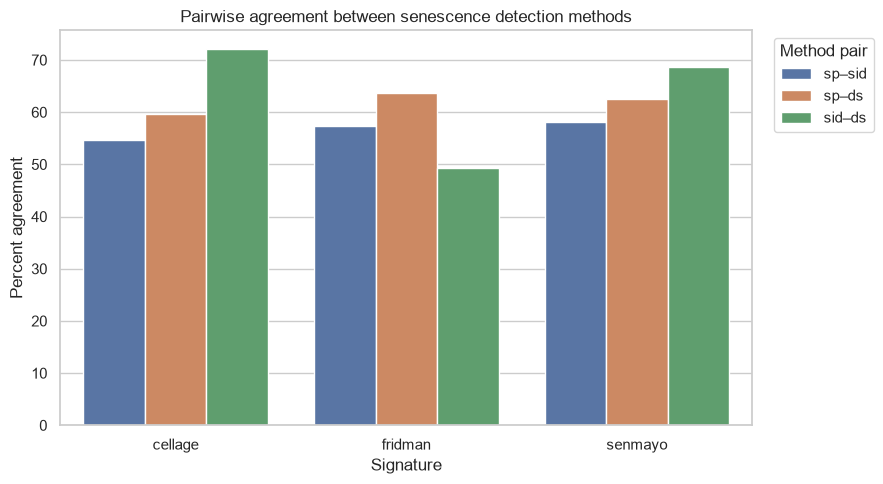

In [108]:
plot_pairwise_summary(
    pair_metrics_df,
    "percent_agreement",
    ylabel="Percent agreement",
    title="Pairwise agreement between senescence detection methods",
)

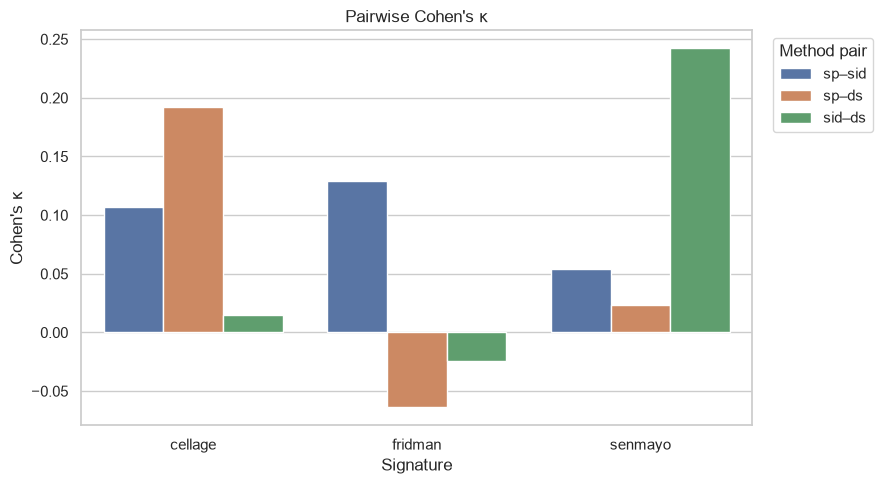

In [109]:
plot_pairwise_summary(
    pair_metrics_df, "cohen_kappa", ylabel="Cohen's κ", title="Pairwise Cohen's κ"
)

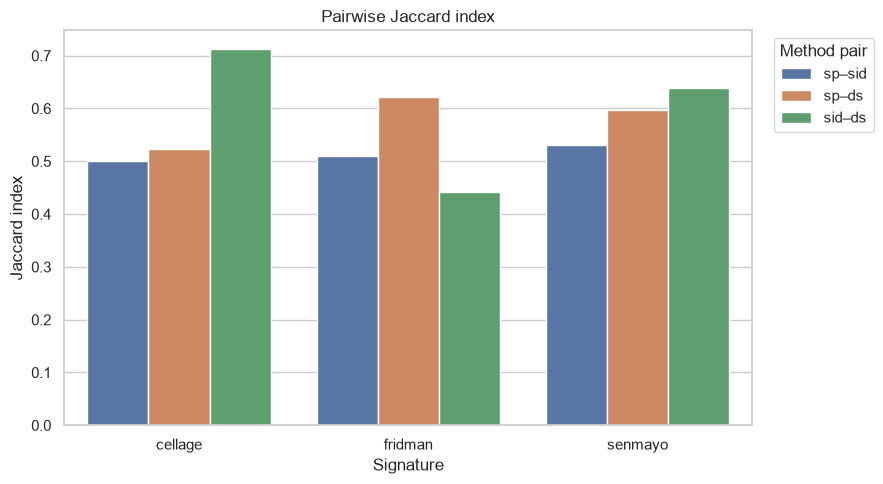

In [110]:
plot_pairwise_summary(
    pair_metrics_df,
    "jaccard_positive",
    ylabel="Jaccard index",
    title="Pairwise Jaccard index",
)

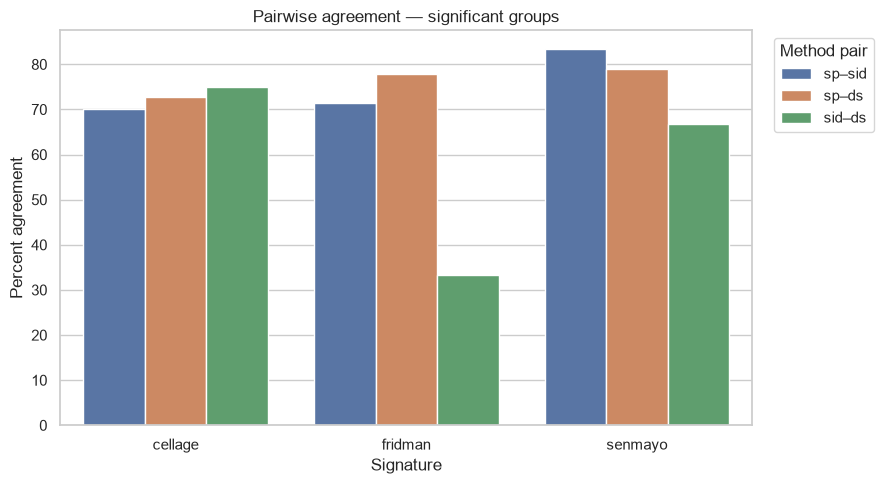

In [111]:
plot_pairwise_summary(
    pair_sig_metrics_df,
    "percent_agreement",
    ylabel="Percent agreement",
    title="Pairwise agreement — significant groups",
)

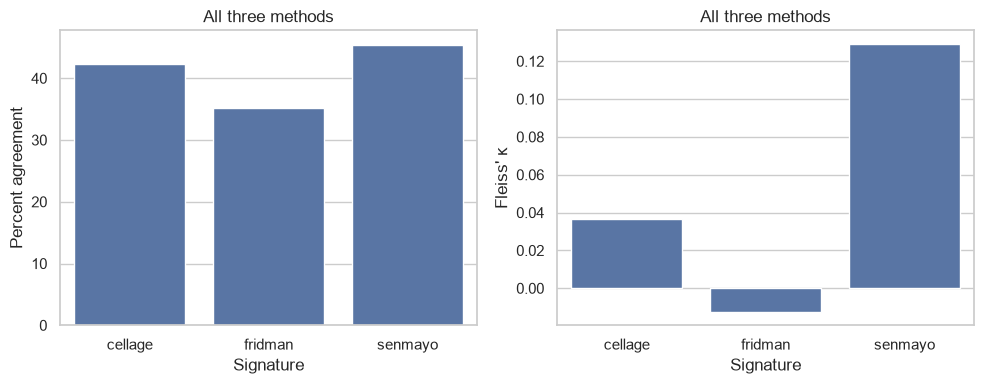

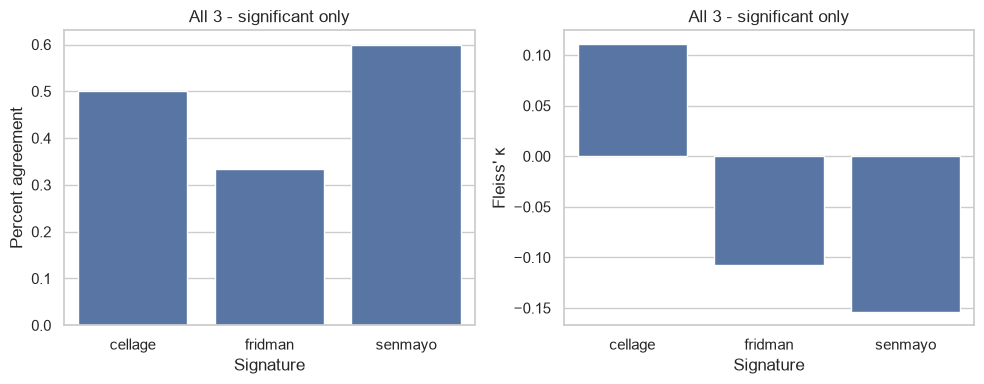

In [112]:
"""Общая визуализация для всех трёх методов (все + только значимые RBC)"""

for i, plot_df in enumerate([all3_metrics_df, all3_sig_metrics_df]):
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    sns.barplot(
        data=plot_df,
        x="signature",
        y="percent_agreement",
        ax=axes[0],
        errorbar=None,
    )
    title = "All three methods"
    if i == 1:
        title = "All 3 - significant only"
    axes[0].set_xlabel("Signature")
    axes[0].set_ylabel("Percent agreement")
    axes[0].set_title(title)

    sns.barplot(
        data=plot_df, x="signature", y="fleiss_kappa", ax=axes[1], errorbar=None
    )

    axes[1].set_xlabel("Signature")
    axes[1].set_ylabel("Fleiss' κ")
    axes[1].set_title(title)

    plt.tight_layout()
    plt.show()

**Визуализация agreement по группам (все RBC)**

In [121]:
def plot_group_agreement(df, agreement_col, method_pair, title_suffix=""):

    signatures = df["signature"].dropna().unique()

    fig, axes = plt.subplots(
        1, len(signatures), figsize=(6 * len(signatures), 6), squeeze=False
    )

    axes = axes[0]

    for ax, signature in zip(axes, signatures):
        sub = df[df["signature"] == signature].copy()

        heatmap_df = sub.pivot(
            index="Tissue_global", columns="cell_type", values=agreement_col
        )

        sns.heatmap(
            heatmap_df,
            ax=ax,
            vmin=0,
            vmax=1,
            cmap="viridis",
            annot=True,
            fmt=".0f",
            cbar=False,
            linewidths=0.5,
        )

        ax.set_title(signature)
        ax.set_xlabel("Cell type")
        ax.set_ylabel("Tissue")

    fig.suptitle(f"{method_pair}: direction agreement {title_suffix}", y=1.02)

    plt.tight_layout()
    plt.show()

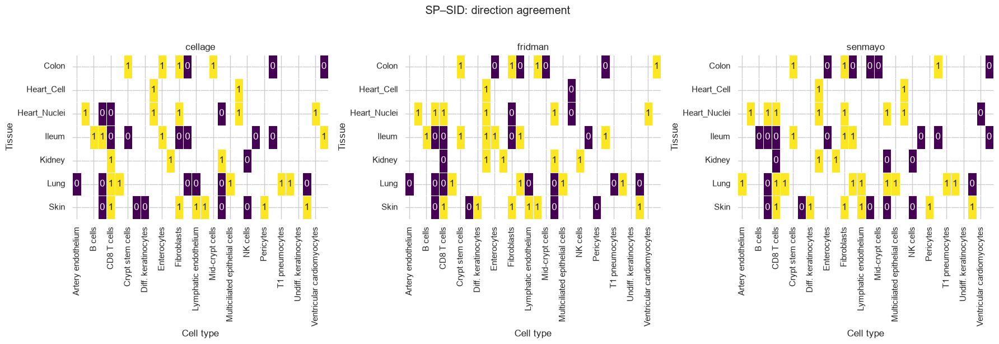

In [114]:
plot_group_agreement(agreement_df, "agreement_sp_sid", "SP–SID")

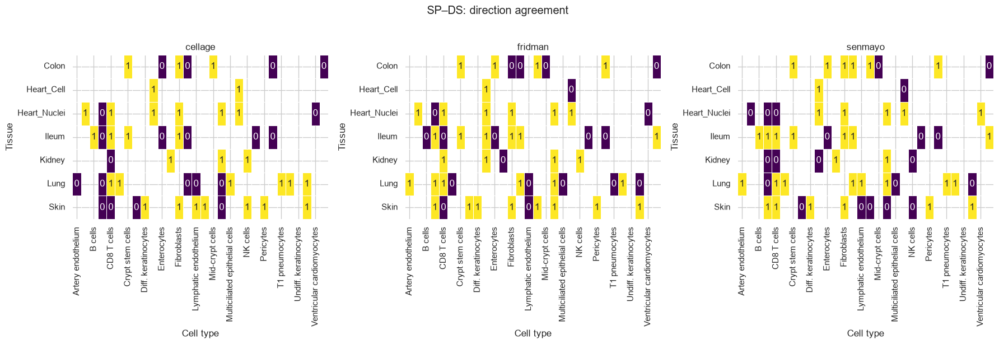

In [115]:
plot_group_agreement(agreement_df, "agreement_sp_ds", "SP–DS")

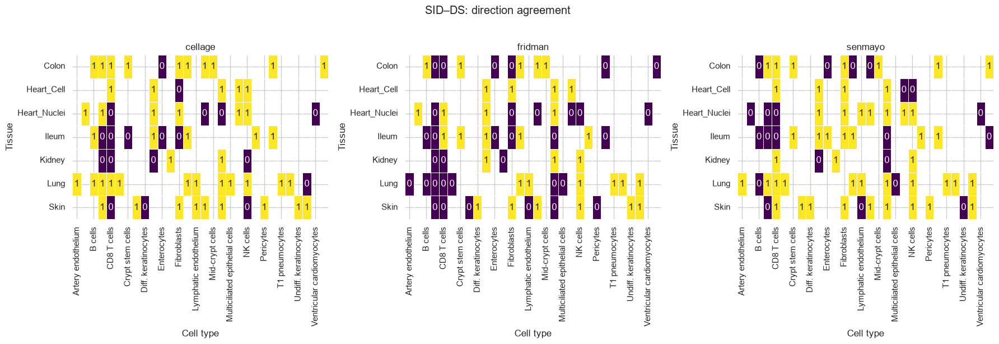

In [116]:
plot_group_agreement(agreement_df, "agreement_sid_ds", "SID–DS")

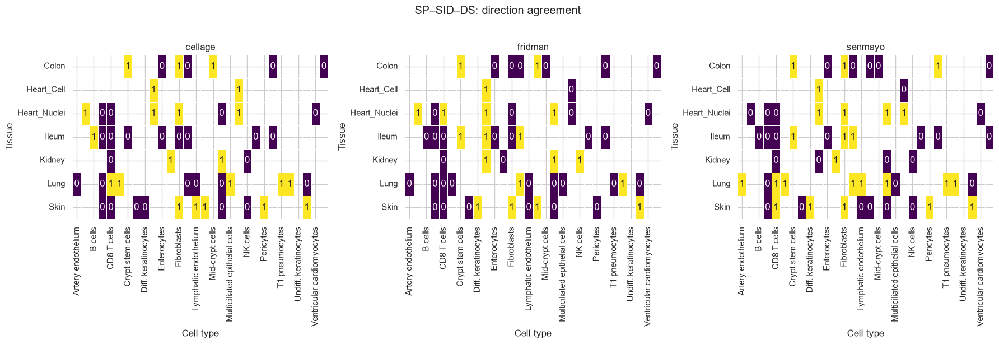

In [117]:
plot_group_agreement(agreement_df, "agreement_all3", "SP–SID–DS")

**Визуализация agreement по группам (только стат.значимые RBC)**

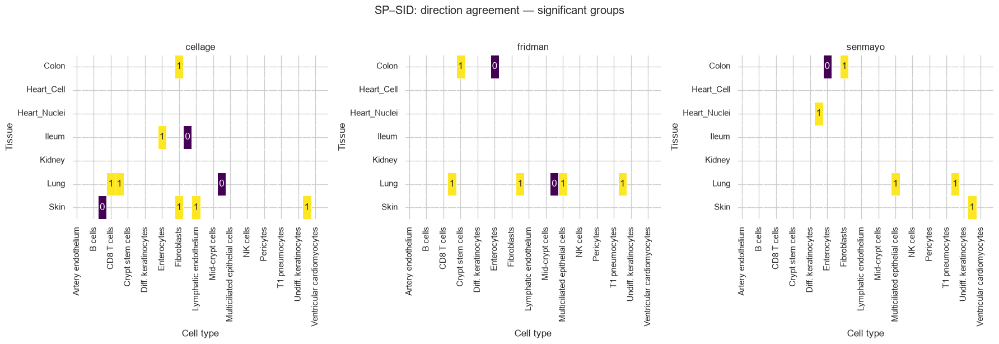

In [123]:
plot_group_agreement(
    agreement_sig_df, "agreement_sp_sid", "SP–SID", title_suffix="— significant groups"
)

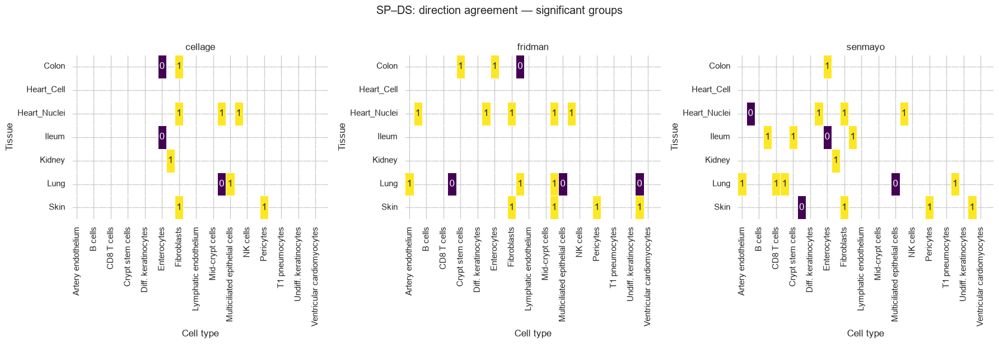

In [124]:
plot_group_agreement(
    agreement_sig_df, "agreement_sp_ds", "SP–DS", title_suffix="— significant groups"
)

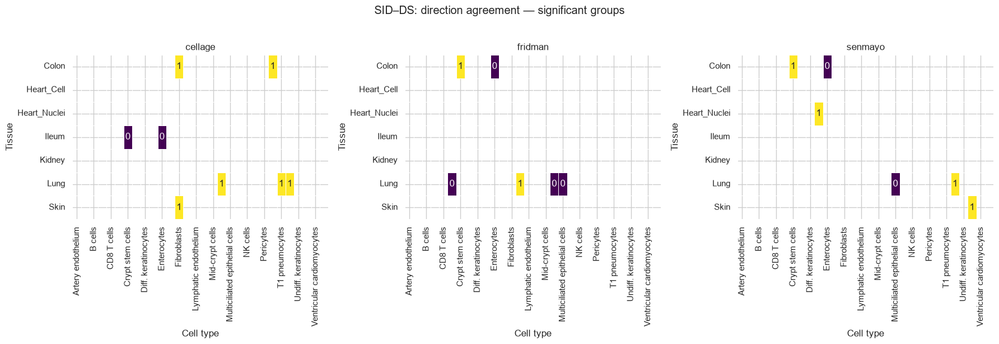

In [125]:
plot_group_agreement(
    agreement_sig_df, "agreement_sid_ds", "SID–DS", title_suffix="— significant groups"
)

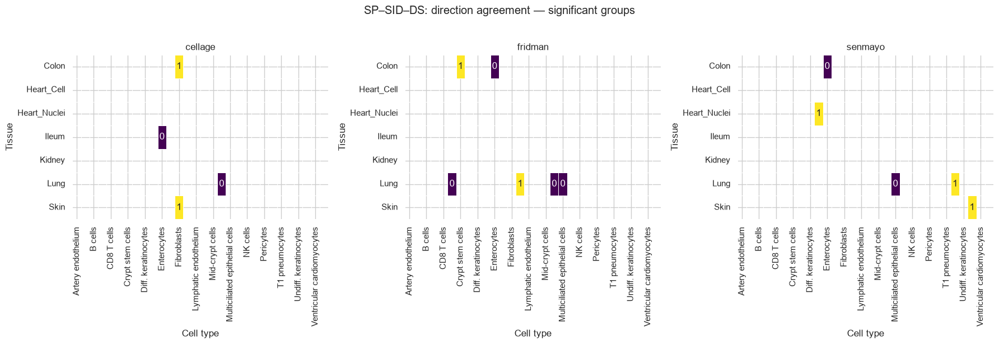

In [126]:
plot_group_agreement(
    agreement_sig_df, "agreement_all3", "SP–SID–DS", title_suffix="— significant groups"
)